# EyePACS -- Module 1 extra data + Module 2 non-longitudinal pretraining

Uses the resized EyePACS dataset
([kaggle.com/datasets/mohlamin/resized-eyepacs-diabetic-retinopathy-dataset](https://www.kaggle.com/datasets/mohlamin/resized-eyepacs-diabetic-retinopathy-dataset),
`all_labels.csv`, ICDR 0-4) for two things:

* **Part A -- Module 1:** builds an EyePACS grading pickle (patient-level split, both eyes of a
  patient stay in the same split) and, optionally, trains DRG-Net's classifier on it.
* **Part B -- Module 2 stage 1:** runs Module 1's lesion segmenters over (a subset of) EyePACS,
  builds per-stage biomarker profiles (EX/HE/MA/SE area + count, LBS), and pretrains the
  Module 2 Generator/Discriminator on single graded images (StarGAN-style stage translation +
  biomarker-profile loss). Checkpoints go to Drive so **notebook 06** can fine-tune from them
  (`USE_NONLONG_PRETRAIN = True` there).

**Round 4:** the EyePACS Module 1 cache is rebuilt with the fine-tuned segmenters on more images
(`PER_GRADE_SUBSET` 3000, was 1500 -- round 3's biomarker losses only saw 7,500 of 88,700 images), images
are retina-cropped and 256 px, the Generator's loss includes the frozen EyePACS grader
(`LAMBDA_GRADER`), and a stage-control check grades the pretrained Generator's outputs with BOTH Module 1
graders (the Discriminator's own stage head, round 3's 74-100 %, graded real images at 17.5 %).

**Run after notebooks 01-03** (needs the FGADR classifier + segmentation checkpoints on Drive).

**Manual prerequisite:** download the Kaggle zip and upload it to `My Drive/Thesis_Datasets/`
(set `EYEPACS_ZIP` below if you named it differently).

**Round 8** (branch `R8-256px-EyePACSGrader`): a fresh **256 px** pretraining (`ROUND_TAG = '_r8'`, `MODULE2_IMAGE_SIZE = 256`, `CONTINUE_ROUND3_PRETRAIN = False`, no grader loss, 80 epochs, ~12-20 h on an L4, resumes after a disconnect). The EyePACS cache is copied from round 5's folder. The stage-control check uses the EyePACS grader only (the FGADR grader is not usable on new data -- `module1/FGADR_GRADER_DIAGNOSIS.md`). Run this before notebook 06.

**Round 9** (branch `R9-Pretrain-Identity-DiffAug`): first short **test runs** that continue round 8's pretraining for 10 epochs each -- A (identity loss on every step + DiffAugment on the critic), B (A + biomarker loss off), C (control) -- each in its own folder, then a comparison cell that names the **winner** by redness and the no-change test. Then the full pretraining with the winner (`PRETRAIN_MODE = 'full'`, `FULL_RUN`). See the round-9 section below Part B's profiles cell.


In [19]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('\u26a0 Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os, glob, json
GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'R9-Pretrain-Identity-DiffAug'  # <-- round 9; 'R8-256px-EyePACSGrader' = round 8, 'R5-Round3Baseline-Fixes' = round 5, 'AllModuleEdits-PreFinals' = rounds 3/4, 'mod-2-NonLongIntegration' = the earlier runs
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"
MODULE2_RUNS_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs')
os.makedirs(MODULE2_RUNS_DIR, exist_ok=True)

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
# New Drive folders for this branch's runs: every Module 1 cache / Module 2 / Module 3 folder below
# gets RUN_SUFFIX, so the mod-2-NonLongIntegration results stay untouched for before/after
# comparison. '' = read/write the earlier folders again.
RUN_SUFFIX = '_prefinals'
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE] + RUN_SUFFIX
# Round 4: every Module 1 cache / Module 2 / Module 3 folder ALSO gets ROUND_TAG, so round 3's results
# (no ROUND_TAG) stay untouched for before/after comparison -- the SAME value in notebooks 04_05 and 06-10.
# Model folders (notebook 11) and the laterality file keep RUN_SUFFIX only. '' = round 3's folders.
# Round 8 (branch R8-256px-EyePACSGrader): a fresh 256 px pretraining in new '_r8' folders (round 5's 128 px run
# can't be continued at 256 px; round 4's 256 px run had the grader loss that painted coloured marks).
# Round 9 (branch R9-Pretrain-Identity-DiffAug): new '_r9' folders. First the short pretraining TEST runs (A/B/C,
# PRETRAIN_MODE = 'tests' below), each continuing round 8's pretraining for 10 epochs in its own folder; then the
# full round-9 pretraining with the winner (PRETRAIN_MODE = 'full'). Round 8's folders are only read.
ROUND_TAG = '_r9'
# Round 5 (branch R5-Round3Baseline-Fixes): round 3's Module 2 settings (128 px, no grader loss, round 3's
# best-epoch rule) + the data fixes (text-safe retina crop, SIFT failures dropped). '_r4' = round 4's folders.
RUN_TAG += ROUND_TAG
# Image preprocessing for every script this notebook runs (fundus_preprocess.py), the same in 04_05-10:
#   DRP_RETINA_CROP '1' = crop to the retina and pad to square before resizing (Tianjin's 3:2 and LongDR's
#     2000x1312 photos were squashed into ovals); '0' = round 3's plain resize.
#   DRP_LONGDR_FOLDER 'FundusImagesColor' = LongDR's raw colour photos. Round 3 used FundusImagesNormalized,
#     on which the lesion segmenters (trained on raw photos) marked 10-30 % of a NORMAL retina as lesion
#     (LBS 0.1-0.34 at grade 0, vs ~0.001 on Tianjin/FIRE) -- 559 of the 917 Module 2 pairs.
os.environ['DRP_RETINA_CROP'] = '1'
os.environ['DRP_LONGDR_FOLDER'] = 'FundusImagesColor'
# Module 2 resolution -- the SAME value in notebooks 06, 08, 09 and 10 (item 4.3; the scripts stop
# with an error on a mismatch).
# Round 4: 'auto' = the size notebook 04_05's grader-resolution check recommends (its
# grader_resolution_check.json in this round's Module 1 cache folder): 256 px when the grader reads real
# Tianjin images clearly better at 256 than at 128 px (kappa +0.05 or more), else 128 (~4x faster). Set a
# number (128 / 256) to override. Run 04_05 to the end BEFORE 09 / 06, so every notebook gets the same size.
MODULE2_IMAGE_SIZE = 256  # round 8: 256 px (notebook 12); round 5: 128 px (round 3); 'auto' = notebook 04_05's recommendation (256 in round 4)
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Notebook 11 on this branch writes its models to drgnet_replication<RUN_SUFFIX>/ (tiled evaluation,
# 200 segmentation epochs, optional EyePACS grader); use those once they exist.
if MODULE1_SOURCE != 'poc' and os.path.isdir(os.path.join(MODULE1_RUNS + RUN_SUFFIX, 'segmentation')):
    MODULE1_RUNS += RUN_SUFFIX
elif MODULE1_SOURCE != 'poc' and RUN_SUFFIX:
    print(f'\u26a0 {MODULE1_RUNS + RUN_SUFFIX} not found -- using the earlier Module 1 models in {MODULE1_RUNS}. '
          'Run notebook 11 on this branch first for the re-trained ones.')
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
# Round 4: notebook 11's fine-tuned combined segmenters (comb_ft_models_*) once all four exist.
if MODULE1_SOURCE == 'drgnet_combined':
    if all(os.path.isfile(os.path.join(MODULE1_RUNS, 'segmentation', f'comb_ft_models_{_l}', 'model_2.pth.tar'))
           for _l in ('ex', 'he', 'ma', 'se')):
        SEG_MODEL_PREFIX = 'comb_ft_models_'
    elif ROUND_TAG:
        print('\u26a0 Fine-tuned segmenters (comb_ft_models_*) not all on Drive yet -- using the 200-epoch '
              'comb_models_*. Run notebook 11 (RUN["comb_seg_ft"]) first for round 4.')
print('Lesion segmenters:', SEG_MODEL_PREFIX + '<lesion>')
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_TAG)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)
if MODULE2_IMAGE_SIZE == 'auto':
    import json as _json
    _res_json = os.path.join(MODULE1_CACHE_DIR, 'grader_resolution_check.json')
    if os.path.isfile(_res_json):
        _res = _json.load(open(_res_json))
        if _res.get('recommended_image_size'):
            MODULE2_IMAGE_SIZE = int(_res['recommended_image_size'])
        else:  # a check file written before the recommended_image_size field
            _gain = max((_res.get('kappa_gain_high_vs_low') or {0: 0}).values())
            MODULE2_IMAGE_SIZE = max(_res['sizes']) if _gain >= 0.05 else min(_res['sizes'])
        print(f'MODULE2_IMAGE_SIZE = {MODULE2_IMAGE_SIZE} (auto, from {_res_json}: {_res.get("recommendation")})')
    else:
        MODULE2_IMAGE_SIZE = 256
        print(f'\u26a0 MODULE2_IMAGE_SIZE = 256 (auto fallback): {_res_json} not found -- run notebook 04_05 to the end '
              'first, or set MODULE2_IMAGE_SIZE by hand. Every Module 2 notebook must use the same size.')

EYEPACS_ZIP = os.path.join(DRIVE_DATA_DIR, 'resized-eyepacs-diabetic-retinopathy-dataset.zip')  # <-- your zip name
if not os.path.isfile(EYEPACS_ZIP):
    _z = sorted(glob.glob(os.path.join(DRIVE_DATA_DIR, '*eyepacs*.zip')) + glob.glob(os.path.join(DRIVE_DATA_DIR, '*EyePACS*.zip')))
    assert _z, f"No EyePACS zip found in {DRIVE_DATA_DIR} -- upload it there first"
    EYEPACS_ZIP = _z[0]
print('EyePACS zip:', EYEPACS_ZIP)

Mounted at /content/drive
Google Drive: 144.8 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Lesion segmenters: comb_ft_models_<lesion>
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r9
EyePACS zip: /content/drive/MyDrive/Thesis_Datasets/resized-eyepacs-diabetic-retinopathy-dataset.zip


In [20]:
# Unzip locally on the Colab VM disk (much faster than reading off Drive). -n = skip existing.
EYEPACS_DIR = '/content/data/eyepacs'
os.makedirs(EYEPACS_DIR, exist_ok=True)
!unzip -q -n "{EYEPACS_ZIP}" -d "{EYEPACS_DIR}"

import pandas as pd
_csv = glob.glob(f'{EYEPACS_DIR}/**/all_labels.csv', recursive=True)
assert _csv, 'all_labels.csv not found in the zip -- check: !ls -R /content/data/eyepacs | head'
LABELS_CSV = _csv[0]
_df = pd.read_csv(LABELS_CSV)
print(LABELS_CSV, _df.shape)
print(_df.head())
print('Columns:', list(_df.columns))  # the loaders auto-detect image/grade columns from these

/content/data/eyepacs/all_labels.csv (88700, 3)
      image  level Usage
0   10_left      0   NaN
1  10_right      0   NaN
2   13_left      0   NaN
3  13_right      0   NaN
4   15_left      1   NaN
Columns: ['image', 'level', 'Usage']


In [21]:
# Clone this repo. Skips cleanly if already cloned in this runtime.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}
REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR} -- check REPO_BRANCH/REPO_CODE_SUBDIR above"
%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch matplotlib scipy torchmetrics torch-fidelity

/content
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


In [22]:
# Item 7.3: EyePACS image sizes (the resized Kaggle copy's sizes are undocumented); first 5,000 images.
!python {REPO_CODE_DIR}/tools/dataset_image_sizes.py eyepacs="{EYEPACS_DIR}" --max-images 5000 --out "{MODULE1_CACHE_DIR}/dataset_image_sizes_eyepacs.json"


eyepacs (/content/data/eyepacs): 5000 images
  most common: 512x512 (5000)
  width  min/median/max: 512 / 512 / 512
  height min/median/max: 512 / 512 / 512
  non-square: 0.0%

Wrote /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r9/dataset_image_sizes_eyepacs.json


## Part A -- Module 1: EyePACS grading data

`COMBINE_WITH_FGADR = True` merges FGADR's pickle in (train on both). That changes the test
set, so keep the FGADR-only run from notebook 02 for comparison with the DRG-Net paper.

In [23]:
COMBINE_WITH_FGADR = False
MAX_PER_GRADE = None   # e.g. 3000 to shorten Module 1 training -- EyePACS is ~73% grade 0

PKL_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_pkl')
os.makedirs(PKL_DIR, exist_ok=True)
# RUN_SUFFIX: built with the fixed Usage handling (blank = original training images -> train;
# the earlier pickle had 0 training images)
EYEPACS_PKL = os.path.join(PKL_DIR, f'eyepacs_classification_pkl{RUN_SUFFIX}.pkl')
_extra = ''
if COMBINE_WITH_FGADR:
    _extra += f' --combine-with "{os.path.join(PKL_DIR, "fgadr_classification_pkl.pkl")}"'
if MAX_PER_GRADE:
    _extra += f' --max-per-grade {MAX_PER_GRADE}'
%cd {REPO_CODE_DIR}
!python module1/dataprep/make_eyepacs_classification_pkl.py --eyepacs-root "{EYEPACS_DIR}" --out "{EYEPACS_PKL}"{_extra}

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ 88700 labelled images found (0 labelled but missing on disk)
  Official split from column 'Usage': ['private', 'public'] + 35126 blank (= original training images -> train)
  Official split read from labels CSV column
✓ train: 35126 images, per grade [25810, 2443, 5292, 873, 708]
✓ val  : 10906 images, per grade [8130, 720, 1579, 237, 240]
✓ test : 42668 images, per grade [31402, 3042, 6281, 977, 966]
✓ wrote /content/drive/MyDrive/Thesis_Datasets/module1_pkl/eyepacs_classification_pkl_prefinals.pkl (split=official)


In [24]:
# OPTIONAL (long: ~35k training images at 512px x 25 epochs is many hours on Colab -- set
# MAX_PER_GRADE above to shorten; resumes after a disconnect). Trains DRG-Net's classifier on the EyePACS pickle with
# module1/configs/eyepacs_poc.yaml. Same DRG-Net setup + compatibility patches as notebook 02.
# Notebook 11 (RUN['eyepacs_cls'], on by default on this branch) trains the same grader into the same
# folder -- run it in one of the two notebooks. EyePACS is ~73 % grade 0, so sampling is
# progressively_balanced here (DRG-Net's yaml: instance_balanced) unless MAX_PER_GRADE caps train.
RUN_EYEPACS_CLASSIFIER_TRAINING = False
EYEPACS_SAMPLING = 'progressively_balanced'   # None = DRG-Net's instance_balanced

if RUN_EYEPACS_CLASSIFIER_TRAINING:
    %cd /content
    if not os.path.isdir('/content/dr-joint-learning'):
        !git clone https://github.com/DFKI-Interactive-Machine-Learning/dr-joint-learning.git dr-joint-learning
        !cd dr-joint-learning && git checkout 0da1bbe885f438390a0e94ec486283d9b21d5547
    !sed -i 's/fillcolor=aug_args.value_fill/fill=aug_args.value_fill/' /content/dr-joint-learning/dr_classification/data/transforms.py
    !pip install -q munch self-attention-cv pretrainedmodels cnn_finetune ipdb
    # Checkpoint/resume (same patch as notebook 11): the training state is saved every epoch on the
    # VM disk and copied to Drive every 5 epochs and at the end (rewriting it on Drive every epoch
    # would fill the Drive with old copies); re-running this cell after a disconnect continues from
    # the last Drive copy.
    !python {REPO_CODE_DIR}/module1/drgnet_resume_patch.py /content/dr-joint-learning
    import re, shutil
    # Where notebooks 04_05-10 look for CLASSIFIER_RUN = 'eyepacs' (same folder notebook 11 uses).
    _cls_root = (os.path.join(DRIVE_DATA_DIR, 'module1_runs') if MODULE1_SOURCE == 'poc'
                 else os.path.join(DRIVE_DATA_DIR, 'module1_runs', 'drgnet_replication' + RUN_SUFFIX))
    _drive_saves = f'{_cls_root}/classification/eyepacs/saves'
    _local_saves = '/content/drg_local/classification/eyepacs/saves'
    os.makedirs(_drive_saves, exist_ok=True); os.makedirs(_local_saves, exist_ok=True)
    for _f in os.listdir(_drive_saves):  # new runtime: resume from the Drive copy
        if not os.path.isfile(os.path.join(_local_saves, _f)):
            shutil.copy2(os.path.join(_drive_saves, _f), os.path.join(_local_saves, _f))
    _cfg = open(f'{REPO_CODE_DIR}/module1/configs/eyepacs_poc.yaml').read()
    _cfg = re.sub(r"save_path: .*", f"save_path: '{_local_saves}'", _cfg, count=1)
    _cfg = re.sub(r"log_path: .*", "log_path: '/content/drg_local/classification/eyepacs/logs'", _cfg, count=1)
    _cfg = re.sub(r"data_index: .*", f"data_index: '{EYEPACS_PKL}'", _cfg, count=1)
    if EYEPACS_SAMPLING and not MAX_PER_GRADE:
        _cfg = re.sub(r"sampling_strategy: \w+", f"sampling_strategy: {EYEPACS_SAMPLING}", _cfg, count=1)
    open('/content/dr-joint-learning/dr_classification/configs/eyepacs_poc.yaml', 'w').write(_cfg)
    %cd /content/dr-joint-learning/dr_classification
    !DRG_CLS_RESUME=1 DRG_CLS_MIRROR_DIR="{_drive_saves}" DRG_CLS_MIRROR_EVERY=5 python main.py -c configs/eyepacs_poc.yaml -overwrite
    for _f in ('best_validation_weights.pt', 'final_weights.pt', 'resume_state.pt'):
        if os.path.isfile(os.path.join(_local_saves, _f)):
            shutil.copy2(os.path.join(_local_saves, _f), os.path.join(_drive_saves, _f))
    assert os.path.isfile(os.path.join(_drive_saves, 'final_weights.pt')), (
        f'final_weights.pt not saved to {_drive_saves} -- is your Google Drive full? (drive.google.com/settings/storage)')
    %cd {REPO_CODE_DIR}
else:
    print('Skipped (RUN_EYEPACS_CLASSIFIER_TRAINING = False).')

Skipped (RUN_EYEPACS_CLASSIFIER_TRAINING = False).


## Part B -- Module 2 stage 1: biomarker profiles + non-longitudinal pretraining

Module 1 over all ~88k images takes hours, so by default a grade-stratified subset
(`PER_GRADE_SUBSET` images per grade) is cached. `--resume` + `--save-every` let you re-run this
cell after a disconnect and continue where it stopped. The classifier's predicted grade isn't
used here (EyePACS has real labels) -- only the lesion masks/stats matter.

In [25]:
CLASSIFIER_RUN = 'eyepacs'   # Module 1 grader: 'eyepacs' (default, notebook 11) or 'fgadr' -- use the one notebook 04_05's comparison recommends
if not glob.glob(os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves', '*.pt')):
    print(f'\u26a0 No {CLASSIFIER_RUN} grader in {MODULE1_RUNS} yet -- using the FGADR one')
    CLASSIFIER_RUN = 'fgadr'

# Locate the Module 1 classifier + segmentation checkpoints (same discovery logic as
# notebooks 04-08). HE/SE are included automatically once they exist on Drive.
SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves')
# Classifier input normalisation must match its training config (eyepacs_poc.yaml differs).
CLS_NORM_ARGS = ' --classifier-norm eyepacs' if CLASSIFIER_RUN == 'eyepacs' else ''

# EyePACS: best_validation_weights.pt (picked on the Kaggle public test, kept apart from its test set);
# FGADR: final_weights.pt (its "validation" set IS its test set, so the best-validation pick is optimistic).
_pref  = (['best_validation_weights.pt', 'final_weights.pt'] if CLASSIFIER_RUN == 'eyepacs'
          else ['final_weights.pt', 'best_validation_weights.pt'])
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

SEG_ARGS = ''
for _lesion in ['EX', 'MA', 'HE', 'SE']:
    _p = os.path.join(SEG_DIR, f'{SEG_MODEL_PREFIX}{_lesion.lower()}', 'model_2.pth.tar')
    if os.path.isfile(_p):
        SEG_ARGS += f' --seg-checkpoint {_lesion}="{_p}"'
    print(f'{_lesion} seg :', _p if os.path.isfile(_p) else 'not trained yet')
assert 'EX=' in SEG_ARGS and 'MA=' in SEG_ARGS, f'EX/MA segmentation checkpoints missing in {SEG_DIR} -- run notebook 03 (poc) or 11 (drgnet) first'
print('classifier:', CLS_CKPT)

EX seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ex/model_2.pth.tar
MA seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ma/model_2.pth.tar
HE seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_he/model_2.pth.tar
SE seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_se/model_2.pth.tar
classifier: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/classification/eyepacs/saves/best_validation_weights.pt


In [26]:
# Images per grade to run Module 1 on; None = all images (hours). Round 4: 3000 (was 1500) -> ~13k images
# (grades 3/4 have ~2,000 each), ~2-3 h on an L4; the biomarker losses only apply to cached images.
PER_GRADE_SUBSET = 3000

from crosssectional_dataset import load_labels, sample_per_grade
_labels = load_labels(LABELS_CSV)
if PER_GRADE_SUBSET:
    _labels = sample_per_grade(_labels, PER_GRADE_SUBSET, seed=0)
IMAGE_LIST = '/content/eyepacs_module1_subset.txt'
_labels['image_id'].to_csv(IMAGE_LIST, index=False, header=False)
print(f'{len(_labels)} images queued, per grade:', _labels['grade'].value_counts().sort_index().tolist())

EYEPACS_CACHE = os.path.join(MODULE1_CACHE_DIR, 'module1_outputs_eyepacs.pt')
# Round 5: reuse round 4's EyePACS cache (the same ~13k images, 2-3 h to rebuild) -- copied, round 4 untouched.
# Its .meta.json (the models / settings it was built with) is copied too: --resume only continues a cache whose
# .meta.json matches, and rebuilds from scratch otherwise. A marker file records that the copy finished, so an
# interrupted run (or one from before this fix, which copied the .pt without its .meta.json and started
# rebuilding) is replaced by a fresh copy; the leftover local copy on the runtime disk is removed as well.
# EyePACS photos have no text overlays, so the crop fix doesn't change it. False = rebuild it.
REUSE_ROUND4_EYEPACS_CACHE = True
# Round 8: copied from round 5's folder (itself round 4's cache: same images, models and 256 px masks), else round 4's.
REUSE_EYEPACS_CACHE_FROM = ('_r8', '_r5', '_r4')  # round 9: round 8's copy first (same images, models, 256 px masks)
_r4_cache = next((EYEPACS_CACHE.replace(ROUND_TAG, _t) for _t in REUSE_EYEPACS_CACHE_FROM
                  if ROUND_TAG not in ('', _t) and os.path.isfile(EYEPACS_CACHE.replace(ROUND_TAG, _t))), None)
_r4_marker = EYEPACS_CACHE + '.copied_from_r4'
if REUSE_ROUND4_EYEPACS_CACHE and _r4_cache and os.path.isfile(_r4_cache) and not os.path.isfile(_r4_marker):
    import shutil
    import sys
    sys.path.insert(0, REPO_CODE_DIR)
    from drive_io import local_twin
    shutil.copyfile(_r4_cache, EYEPACS_CACHE)
    if os.path.isfile(_r4_cache + '.meta.json'):
        shutil.copyfile(_r4_cache + '.meta.json', EYEPACS_CACHE + '.meta.json')
    else:
        print('\u26a0 round 4 cache has no .meta.json -- the script below will rebuild it from scratch')
    if local_twin(EYEPACS_CACHE) != EYEPACS_CACHE and os.path.isfile(local_twin(EYEPACS_CACHE)):
        os.remove(local_twin(EYEPACS_CACHE))  # partial rebuild on the runtime disk -- resume from the copy instead
    assert os.path.getsize(EYEPACS_CACHE) == os.path.getsize(_r4_cache), 'copy incomplete -- is Google Drive full?'
    open(_r4_marker, 'w').write(_r4_cache)
    print(f'✓ Copied the earlier EyePACS cache {_r4_cache} -> {EYEPACS_CACHE}')
%cd {REPO_CODE_DIR}/module1
!python apply_to_progression_data.py --images-dir "{EYEPACS_DIR}" \
    --classifier-checkpoint "{CLS_CKPT}"{SEG_ARGS}{CLS_NORM_ARGS} \
    --image-list "{IMAGE_LIST}" --mask-size {max(256, MODULE2_IMAGE_SIZE)} \
    --out "{EYEPACS_CACHE}" --resume --save-every 200 --quiet
%cd {REPO_CODE_DIR}

  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
13001 images queued, per grade: [3000, 3000, 3000, 2087, 1914]
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/module1
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
--image-list: 13001 of 13001 listed images found under /content/data/eyepacs
--resume: 13001 images already cached in /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r9/module1_outputs_eyepacs.pt, skipping them
✓ wrote 13001 entries to /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r9/module1_outputs_eyepacs.pt
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ 13001/88700 labelled images found in the Module 1 cache
✓ Wrote /content/drive/MyDrive/Thesis_Datasets/module2_runs/stage_biomarker_profiles_drgnet_comb_prefinals_r9.json
  stage 0: n=3000, characteristic lesions: ['HE', 'EX']
  stage 1: n=3000, characteristic lesions: ['HE', 'EX', 'MA']
  stage 2: n=3000, characteristic lesions: ['HE', 'EX', 'MA', 'SE']
  stage 3: n=2087, characteristic lesions: ['HE', 'EX', 'MA', 'SE']
  stage 4: n=1914, characteristic lesions: ['HE', 'EX', 'SE', 'MA']
  0->1: biggest shifts MA_area (d=+0.56), MA_count (d=+0.50), HE_count (d=+0.24); shared: ['HE_area', 'EX_count', 'EX_area', 'SE_area', 'SE_count']
  1->2: biggest shifts lbs (d=+0.85), HE_area (d=+0.78), HE_count (d=+0.71); shared: -
  2->3: biggest shifts HE_count (d=+1.10), lbs (d=+0.99), HE_area (d=+0.98); shared: -
  3->4: biggest shifts MA_count (d=-0.46), MA_area (d=-0.45), SE_count

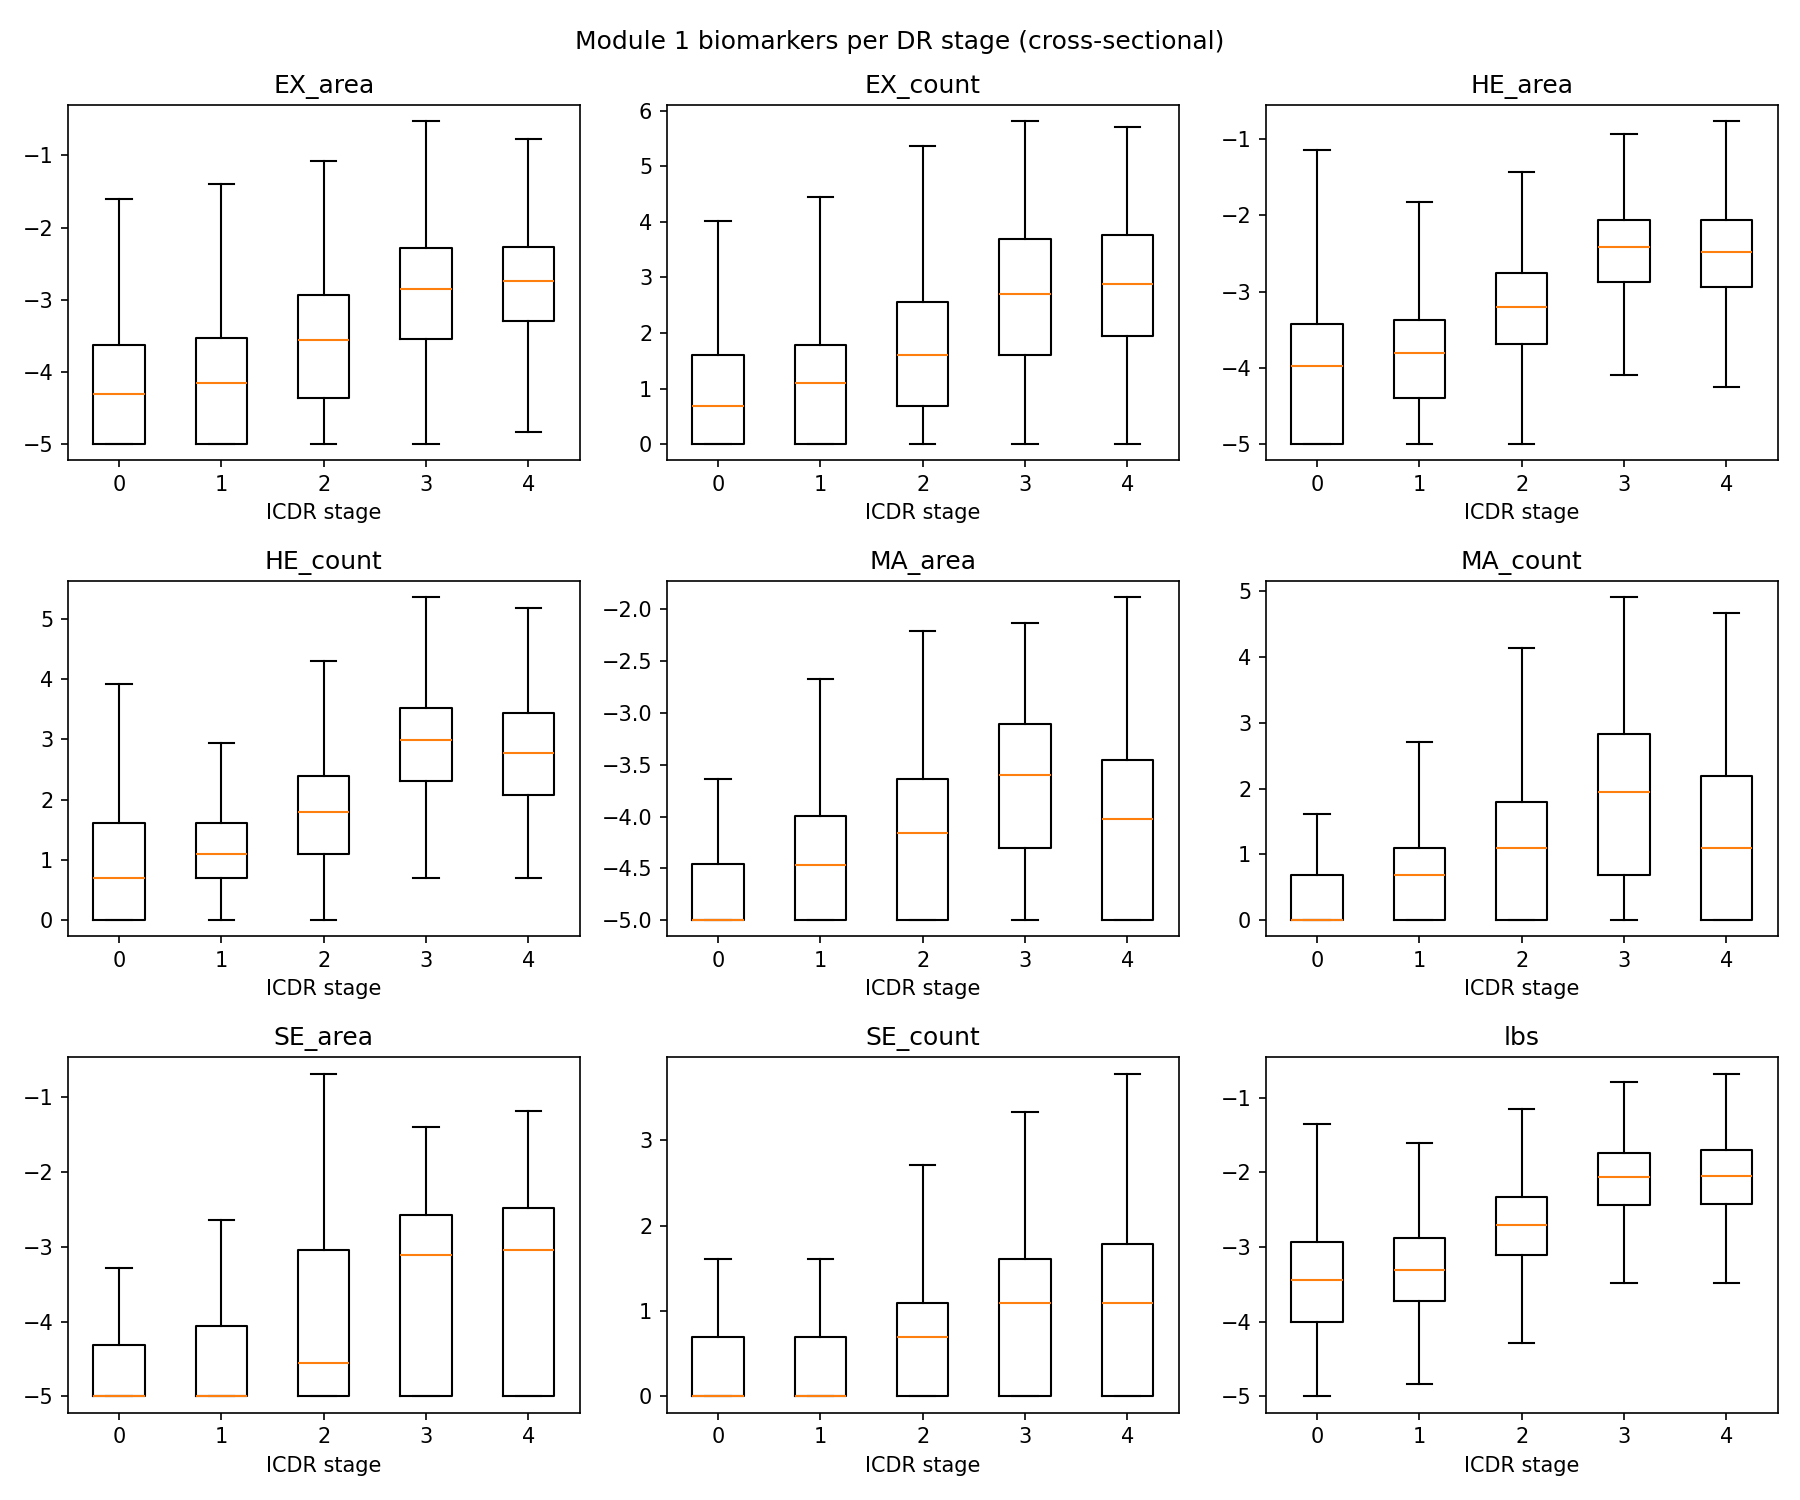

In [27]:
# Which biomarkers characterise each stage / change between adjacent stages.
PROFILES_JSON = os.path.join(MODULE2_RUNS_DIR, f'stage_biomarker_profiles{RUN_TAG}.json')
PROFILES_FIG = os.path.join(MODULE2_RUNS_DIR, f'stage_biomarker_profiles{RUN_TAG}.png')
!python stage_biomarker_profiles.py --module1-cache "{EYEPACS_CACHE}" --labels-csv "{LABELS_CSV}" \
    --out "{PROFILES_JSON}" --fig "{PROFILES_FIG}"

from IPython.display import Image as IPImage, display
display(IPImage(PROFILES_FIG))

## Round 9 -- pretraining test runs (red streaks)

Short test runs that continue round 8's pretraining for 10 epochs with different settings, then a comparison cell that **prints the winner**. Run the notebook once per test run (`TEST_RUN = 'A'`, then `'B'`, optionally `'C'`), then set `PRETRAIN_MODE = 'full'` and `FULL_RUN` to the winner for the full pretraining (the three cells after the settings cell; skipped in test mode).


In [28]:
# Round 9 -- red streaks. Round 8's pretrained Generator satisfied two easily fooled judges (the critic's stage head: 47.5 %
# on real images but ~100 % "correct" on fakes; the image-only biomarker regressor) with red streaks / texture, and asking
# for stage 0 gave outputs the EyePACS grader read as grade 4 in 40 % of cases. Short TEST runs first (~2.5-3 h each on an
# L4), each continuing round 8's pretraining for TEST_EPOCHS in its own folder (round 8's folder is only read):
#   'A'  identity loss on every image every step + DiffAugment on the critic
#   'B'  A + biomarker loss off (lambda_bio 0) -- is the regressor the source of the red?
#   'C'  control: no changes, same extra epochs -- does extra training alone change anything?
#   'D'  A + mirror (reflect) padding in the Generator, 15 epochs. Tests A and B left the streaks unchanged and the
#        patterns sit in the same places in every image. Step 1 (no training) showed round 8's Generator DEPENDS on its
#        zero padding: with reflect padding and no retraining the images fall apart. Networks use zero padding to know
#        where they are in the image -- a likely source of fixed-position patterns. D retrains with reflect padding
#        (15 epochs, not 10: it starts from that broken state). Bilinear up-sampling changed nothing, so it is left out.
#   'E'  FRESH pretraining from scratch (not from round 8) with A's settings + reflect padding. Tests A, B and D all
#        continued from round 8, whose Generator AND critic had learned a fixed texture per stage (a "stage signature":
#        bars at 1, crosshatch at 3, bands at 4) -- the critic keeps rewarding it. E trains E_EPOCHS (20 first, ~6 h) and
#        is compared with round 8's OWN epoch-20 snapshot (same epochs). If E works, set E_EPOCHS = 80 and Run all: the
#        SAME run continues to the full pretraining (~18 h more) and becomes round 9's pretrained Generator.
# Step 1 (no training, ~15 min once, then reused) stays as a record: round 8's Generator with bilinear / reflect / both.
# Run the notebook once per test run (Runtime -> Run all, with TEST_RUN = 'A', then 'B', then optionally 'C'; separate
# sessions or accounts are fine). The comparison cell at the end compares every finished run with round 8 and prints the
# winner. Then set PRETRAIN_MODE = 'full' and FULL_RUN = the winner for the full round-9 pretraining (fresh, 80 epochs).
PRETRAIN_MODE = 'tests'   # 'tests' (now) | 'full' (after the verdict)
TEST_RUN = 'E'            # which test run this session trains: 'A'-'E' (A, B, D are done)
E_EPOCHS = 80             # test E: done to 40; 60 = continue with the stronger identity loss (~6 h); 80 to finish
E_LAMBDA_ID = 20          # test E's identity-loss weight from epoch 41 (epochs 1-40: 5). At 40 epochs E had no red
                          # streaks but a dark spot on the optic disc in every output and a pink stage-0 cast: the
                          # 'keep the eye as it is' loss was too weak against the stage / realism losses.
FULL_RUN = 'A'            # PRETRAIN_MODE = 'full' only: the winner the comparison cell names
TEST_EPOCHS = 10
TEST_EPOCHS_FOR = {'D': 15}
FRESH_RUNS = ('E',)  # start from scratch (no round-8 state); trained to E_EPOCHS in total  # D starts from a Generator that breaks under reflect padding: more room to recover
TEST_SETTINGS = {
    'A': {'label': 'identity every step + DiffAugment',
          'flags': ' --identity-every-step --diffaugment "color,translation,cutout"'},
    'B': {'label': 'identity every step + DiffAugment + biomarker loss off',
          'flags': ' --identity-every-step --diffaugment "color,translation,cutout" --lambda-bio 0 --lambda-mono 0'},
    'C': {'label': 'control (round 8 settings, same extra epochs)', 'flags': ''},
    'D': {'label': 'A + mirror (reflect) padding, 15 epochs',
          'flags': ' --identity-every-step --diffaugment "color,translation,cutout"'},
    'E': {'label': 'fresh from scratch: A + mirror (reflect) padding',
          'flags': ' --identity-every-step --diffaugment "color,translation,cutout"'},
}
# Step 1's Generator-layer variants (base_model.apply_render_options -- no weights change, round 8's checkpoint loads)
RENDER_VARIANTS = {'bilinear': ' --g-upsample bilinear', 'reflect': ' --g-padding reflect',
                   'both': ' --g-upsample bilinear --g-padding reflect'}
RUN_RENDER = {'D': ' --g-padding reflect', 'E': ' --g-padding reflect'}  # Generator-layer flags per test run (training AND every check of that run)
assert PRETRAIN_MODE in ('tests', 'full') and TEST_RUN in TEST_SETTINGS and FULL_RUN in TEST_SETTINGS
R8_NONLONG_DIR = os.path.join(MODULE2_RUNS_DIR, 'nonlong_pretrain' + RUN_TAG.replace(ROUND_TAG, '_r8'))
TESTS_DIR = os.path.join(MODULE2_RUNS_DIR, 'round9_pretrain_tests')  # comparison results (round 8 baseline check, verdict)
os.makedirs(TESTS_DIR, exist_ok=True)
def test_dir(run):
    return os.path.join(MODULE2_RUNS_DIR, f'nonlong_pretrain{RUN_TAG}test_{run}')
CLS_NORM = 'eyepacs' if CLASSIFIER_RUN == 'eyepacs' else 'fgadr'
_EYEPACS_GRADER = os.path.join(MODULE1_RUNS, 'classification', 'eyepacs', 'saves', 'best_validation_weights.pt')
assert os.path.isfile(_EYEPACS_GRADER), f'{_EYEPACS_GRADER} not found -- the stage checks need the EyePACS grader'
def render_flags(run):
    """Generator-layer flags of a test run ('' = as built): D = reflect padding."""
    return RUN_RENDER.get(run, '')
def run_flags(run):
    """All training flags of a test run (E: + its identity weight E_LAMBDA_ID)."""
    return TEST_SETTINGS[run]['flags'] + render_flags(run) + (f' --lambda-id {E_LAMBDA_ID}' if run == 'E' else '')
def check_has_targeted(path):
    """A stage-check JSON with the strong-streak-area and disc-darkening numbers (test E's verdict uses them)."""
    return os.path.isfile(path) and 'mean_disc_darkening' in json.load(open(path))
def stage_check(generator, out_json, extra='', grid=None):
    """tools/stage_control_check.py on the pretraining's held-out EyePACS images (EyePACS grader only), incl. round 9's
    no-change and redness numbers. Same images for every Generator (same seeds), so the runs compare directly.
    extra = Generator-layer flags (--g-upsample / --g-padding); grid = optional sample-grid .jpg."""
    get_ipython().run_line_magic('cd', REPO_CODE_DIR)
    _grid = f' --grid-out "{grid}"' if grid else ''
    get_ipython().system(f'python tools/stage_control_check.py --generator "{generator}" --image-size {MODULE2_IMAGE_SIZE} '
                         f'--dataset-dir "{EYEPACS_DIR}" --preset eyepacs_resized --module1-cache "{EYEPACS_CACHE}" '
                         f'--grader eyepacs="{_EYEPACS_GRADER}:eyepacs" --per-grade 40{extra}{_grid} --out "{out_json}"')
def check_is_current(path):
    """A stage-check JSON with round 9's tint / streak split (older ones are recomputed by the cells below)."""
    return os.path.isfile(path) and 'mean_streak_redness' in json.load(open(path))
print(f'PRETRAIN_MODE = {PRETRAIN_MODE!r}' + (f' | TEST_RUN = {TEST_RUN!r}: {TEST_SETTINGS[TEST_RUN]["label"]} -> {test_dir(TEST_RUN)}'
      if PRETRAIN_MODE == 'tests' else f' | FULL_RUN = {FULL_RUN!r}: {TEST_SETTINGS[FULL_RUN]["label"]}'))


PRETRAIN_MODE = 'tests' | TEST_RUN = 'E': fresh from scratch: A + mirror (reflect) padding -> /content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb_prefinals_r9test_E


In [29]:
if PRETRAIN_MODE == 'full':
    # Stage-1 pretraining. Saved straight to Drive so notebook 06 can fine-tune from it in a later
    # session. NUM_EPOCHS: 40 (was 20); lower NUM_EPOCHS / SAMPLES_PER_EPOCH for a quicker first run.
    # Training state is saved every epoch on the runtime's disk and copied to Drive (resume_state.pt)
    # every 10 epochs and after the last one -- after a disconnect, re-run this cell and it continues
    # from the last Drive copy; raising NUM_EPOCHS later continues the same run. To start over, delete
    # it and restart the runtime.
    # Round 5: 80 -- round 3's pretraining was still improving at epoch 40 (stage-head accuracy on real images
    # 0.175, below chance). With CONTINUE_ROUND3_PRETRAIN it continues round 3's run for 40 more epochs.
    # Round 8: 80 at 256 px (the same budget as round 5's 128 px run, so the size is the only change): roughly
    # 12-20 h on an L4 -- it resumes after a disconnect; lower it for a quicker first look.
    NUM_EPOCHS = 80
    SAMPLES_PER_EPOCH = 20000
    # Round 4: frozen-grader loss with the grader found above (CLS_CKPT -- EyePACS by default; gan_guidance.py).
    # 0 = off (round 3). PRETRAIN_BATCH_SIZE 8 at 256 px with the grader in the loss (16 at 128 px, round 3).
    # At 256 px expect roughly 6-10 h for 40 epochs on an L4 -- it resumes after a disconnect.
    LAMBDA_GRADER = 0.0  # rounds 5, 8 and 9: off, as in round 3
    CLS_NORM = 'eyepacs' if CLASSIFIER_RUN == 'eyepacs' else 'fgadr'
    PRETRAIN_BATCH_SIZE = 16 if MODULE2_IMAGE_SIZE <= 128 else 8
    NONLONG_DIR = os.path.join(MODULE2_RUNS_DIR, 'nonlong_pretrain' + RUN_TAG)
    # Round 9: the full run uses the test winner's settings (FULL_RUN, set in the round-9 settings cell above).
    FULL_FLAGS = run_flags(FULL_RUN)
    print(f'Full round-9 pretraining with test-run {FULL_RUN} settings: {TEST_SETTINGS[FULL_RUN]["label"]}')
    # Round 5: continue round 3's pretraining (40 epochs, 128 px, no grader loss) instead of starting over. Round 3's
    # resume_state.pt is COPIED into this round's folder first, so round 3's own files are never written to.
    CONTINUE_ROUND3_PRETRAIN = False  # round 8: start fresh at 256 px (round 3's state is 128 px); round 5: True
    ROUND3_NONLONG_DIR = os.path.join(MODULE2_RUNS_DIR, 'nonlong_pretrain' + RUN_TAG[:len(RUN_TAG) - len(ROUND_TAG)])
    _state = os.path.join(NONLONG_DIR, 'resume_state.pt')
    if CONTINUE_ROUND3_PRETRAIN and ROUND_TAG and not os.path.isfile(_state):
        _r3_state = os.path.join(ROUND3_NONLONG_DIR, 'resume_state.pt')
        assert os.path.isfile(_r3_state), f'{_r3_state} not found -- set CONTINUE_ROUND3_PRETRAIN = False to start over'
        assert MODULE2_IMAGE_SIZE == 128, 'round 3 pretrained at 128 px -- set MODULE2_IMAGE_SIZE = 128'
        import shutil
        os.makedirs(NONLONG_DIR, exist_ok=True)
        shutil.copy(_r3_state, _state)
        print(f'✓ Copied round 3 pretraining state {_r3_state} -> {_state} (round 3 untouched)')
    elif os.path.isfile(_state):
        print(f'Continuing this round\'s own pretraining state: {_state}')

    !python train_module2_nonlong_pretrain.py --image-size {MODULE2_IMAGE_SIZE} --dataset-dir "{EYEPACS_DIR}" --preset eyepacs_resized \
        --module1-cache "{EYEPACS_CACHE}" --profiles "{PROFILES_JSON}" \
        --num-epochs {NUM_EPOCHS} --samples-per-epoch {SAMPLES_PER_EPOCH} --num-workers 2 \
        --batch-size {PRETRAIN_BATCH_SIZE} \
        --grader-loss-checkpoint "{CLS_CKPT}" --grader-loss-norm {CLS_NORM} --lambda-grader {LAMBDA_GRADER}{FULL_FLAGS} \
        --save-dir "{NONLONG_DIR}" --sample-dir "{NONLONG_DIR}/samples" \
        --resume-state "{NONLONG_DIR}/resume_state.pt"
    for _f in ('final-G.ckpt', 'final-D.ckpt', 'resume_state.pt'):
        assert os.path.isfile(os.path.join(NONLONG_DIR, _f)) and os.path.getsize(os.path.join(NONLONG_DIR, _f)) > 0, (
            f'{_f} not found in {NONLONG_DIR}: if the training output above ends with an error, training stopped '
            f'early -- fix that and re-run this cell (it resumes); if training finished, your Google Drive may be '
            f'full -- check drive.google.com/settings/storage and empty the Trash.')
    print('Pretrained Generator/Discriminator saved to Drive:', NONLONG_DIR)
else:
    print("Skipped: PRETRAIN_MODE = 'tests' (the round-9 test cells below run instead). Set PRETRAIN_MODE = 'full' after the verdict for the full pretraining.")


Skipped: PRETRAIN_MODE = 'tests' (the round-9 test cells below run instead). Set PRETRAIN_MODE = 'full' after the verdict for the full pretraining.


In [30]:
if PRETRAIN_MODE == 'full':
    # Rows: held-out EyePACS images. Columns: input, then the Generator's stage 0..4 versions.
    _samples = sorted(glob.glob(f'{NONLONG_DIR}/samples/epoch_*.jpg'), key=lambda p: int(p.split('_')[-1].split('.')[0]))
    if _samples:
        print(_samples[-1]); display(IPImage(_samples[-1]))
    _res = os.path.join(NONLONG_DIR, 'nonlong_pretrain_results.json')
    print(json.dumps(json.load(open(_res))['metrics'], indent=2) if os.path.isfile(_res) else 'no results yet')
else:
    print("Skipped: PRETRAIN_MODE = 'tests' (the round-9 test cells below run instead). Set PRETRAIN_MODE = 'full' after the verdict for the full pretraining.")


Skipped: PRETRAIN_MODE = 'tests' (the round-9 test cells below run instead). Set PRETRAIN_MODE = 'full' after the verdict for the full pretraining.


In [31]:
if PRETRAIN_MODE == 'full':
    # Round 4 (item R4-3.4): stage control of the pretrained Generator, graded by BOTH Module 1 graders on held-out
    # EyePACS images (the pretraining's own val split): is a stage-k request read as stage k? The grader that was
    # NOT in the Generator's loss (FGADR by default) is the honest number; 'real_accuracy_at_this_size' is the
    # same grader on the real images at this size -- the ceiling. Compare with D's own stage head above.
    # Round 8: EyePACS only. FGADR grades every Tianjin eye 3 or 4 (module1/FGADR_GRADER_DIAGNOSIS.md), so it can't
    # check anything; with LAMBDA_GRADER = 0 the EyePACS grader isn't in G's loss, so its number is the honest one.
    _gr = {'eyepacs': ('eyepacs/saves/best_validation_weights.pt', 'eyepacs')}
    _gargs = ''.join(f' --grader {n}="{os.path.join(MODULE1_RUNS, "classification", p)}:{norm}"'
                     for n, (p, norm) in _gr.items() if os.path.isfile(os.path.join(MODULE1_RUNS, 'classification', p)))
    STAGE_CONTROL_JSON = os.path.join(NONLONG_DIR, 'stage_control_check.json')
    _render = render_flags(FULL_RUN) or ''  # round 9: the same Generator layers as the full run
    %cd {REPO_CODE_DIR}
    !python tools/stage_control_check.py --generator "{NONLONG_DIR}/final-G.ckpt" --image-size {MODULE2_IMAGE_SIZE} \
        --dataset-dir "{EYEPACS_DIR}" --preset eyepacs_resized --module1-cache "{EYEPACS_CACHE}"{_gargs} \
        --per-grade 40{_render} --out "{STAGE_CONTROL_JSON}"
else:
    print("Skipped: PRETRAIN_MODE = 'tests' (the round-9 test cells below run instead). Set PRETRAIN_MODE = 'full' after the verdict for the full pretraining.")


Skipped: PRETRAIN_MODE = 'tests' (the round-9 test cells below run instead). Set PRETRAIN_MODE = 'full' after the verdict for the full pretraining.


In [32]:
# Round 9: round 8's pretrained Generator through the same check (~5 min, once; reused after). The numbers every test run
# is compared against. Written to round9_pretrain_tests/ -- round 8's own folder is not touched.
R8_CHECK_JSON = os.path.join(TESTS_DIR, 'stage_check_r8.json')
if PRETRAIN_MODE != 'tests':
    print('Skipped (PRETRAIN_MODE = "full")')
elif check_is_current(R8_CHECK_JSON) and os.path.isfile(R8_CHECK_JSON.replace('.json', '.jpg')):
    print('✓ Reusing', R8_CHECK_JSON)
else:
    assert os.path.isfile(os.path.join(R8_NONLONG_DIR, 'final-G.ckpt')), f'round 8 pretraining not found in {R8_NONLONG_DIR}'
    stage_check(os.path.join(R8_NONLONG_DIR, 'final-G.ckpt'), R8_CHECK_JSON, grid=R8_CHECK_JSON.replace('.json', '.jpg'))


✓ Reusing /content/drive/MyDrive/Thesis_Datasets/module2_runs/round9_pretrain_tests/stage_check_r8.json


✓ Reusing /content/drive/MyDrive/Thesis_Datasets/module2_runs/round9_pretrain_tests/stage_check_r8_bilinear.json
✓ Reusing /content/drive/MyDrive/Thesis_Datasets/module2_runs/round9_pretrain_tests/stage_check_r8_reflect.json
✓ Reusing /content/drive/MyDrive/Thesis_Datasets/module2_runs/round9_pretrain_tests/stage_check_r8_both.json


,Generator,streaks (mean),streaks 0,streaks 1,streaks 2,streaks 3,streaks 4,tint (mean),no-change: grade changed,stage ctrl (mean),0 -> graded 4
0,round 8 (as trained),0.0108,0.0126,0.0114,0.0118,0.0102,0.0081,0.0003,42%,29%,40%
1,bilinear,0.0113,0.0133,0.0120,0.0124,0.0105,0.0084,0.0003,38%,29%,38%
2,reflect,0.0497,0.0536,0.0514,0.0458,0.0484,0.0492,0.0337,54%,22%,36%
3,both,0.0497,0.0537,0.0517,0.0459,0.0480,0.0493,0.0340,53%,21%,30%



STEP 1 (record only -- test D always trains with reflect padding):
  bilinear : streaks 0.0113 (105% of round 8 as trained), no-change image change 0.019 (round 8: 0.017)
  reflect  : streaks 0.0497 (460% of round 8 as trained), no-change image change 0.357 (round 8: 0.017) -> images BREAK without retraining: the Generator depends on this layer; only retraining (test D) can judge it
  both     : streaks 0.0497 (460% of round 8 as trained), no-change image change 0.355 (round 8: 0.017) -> images BREAK without retraining: the Generator depends on this layer; only retraining (test D) can judge it

round 8 (as trained) -- rows: one held-out image per grade; columns: input, then stages 0-4


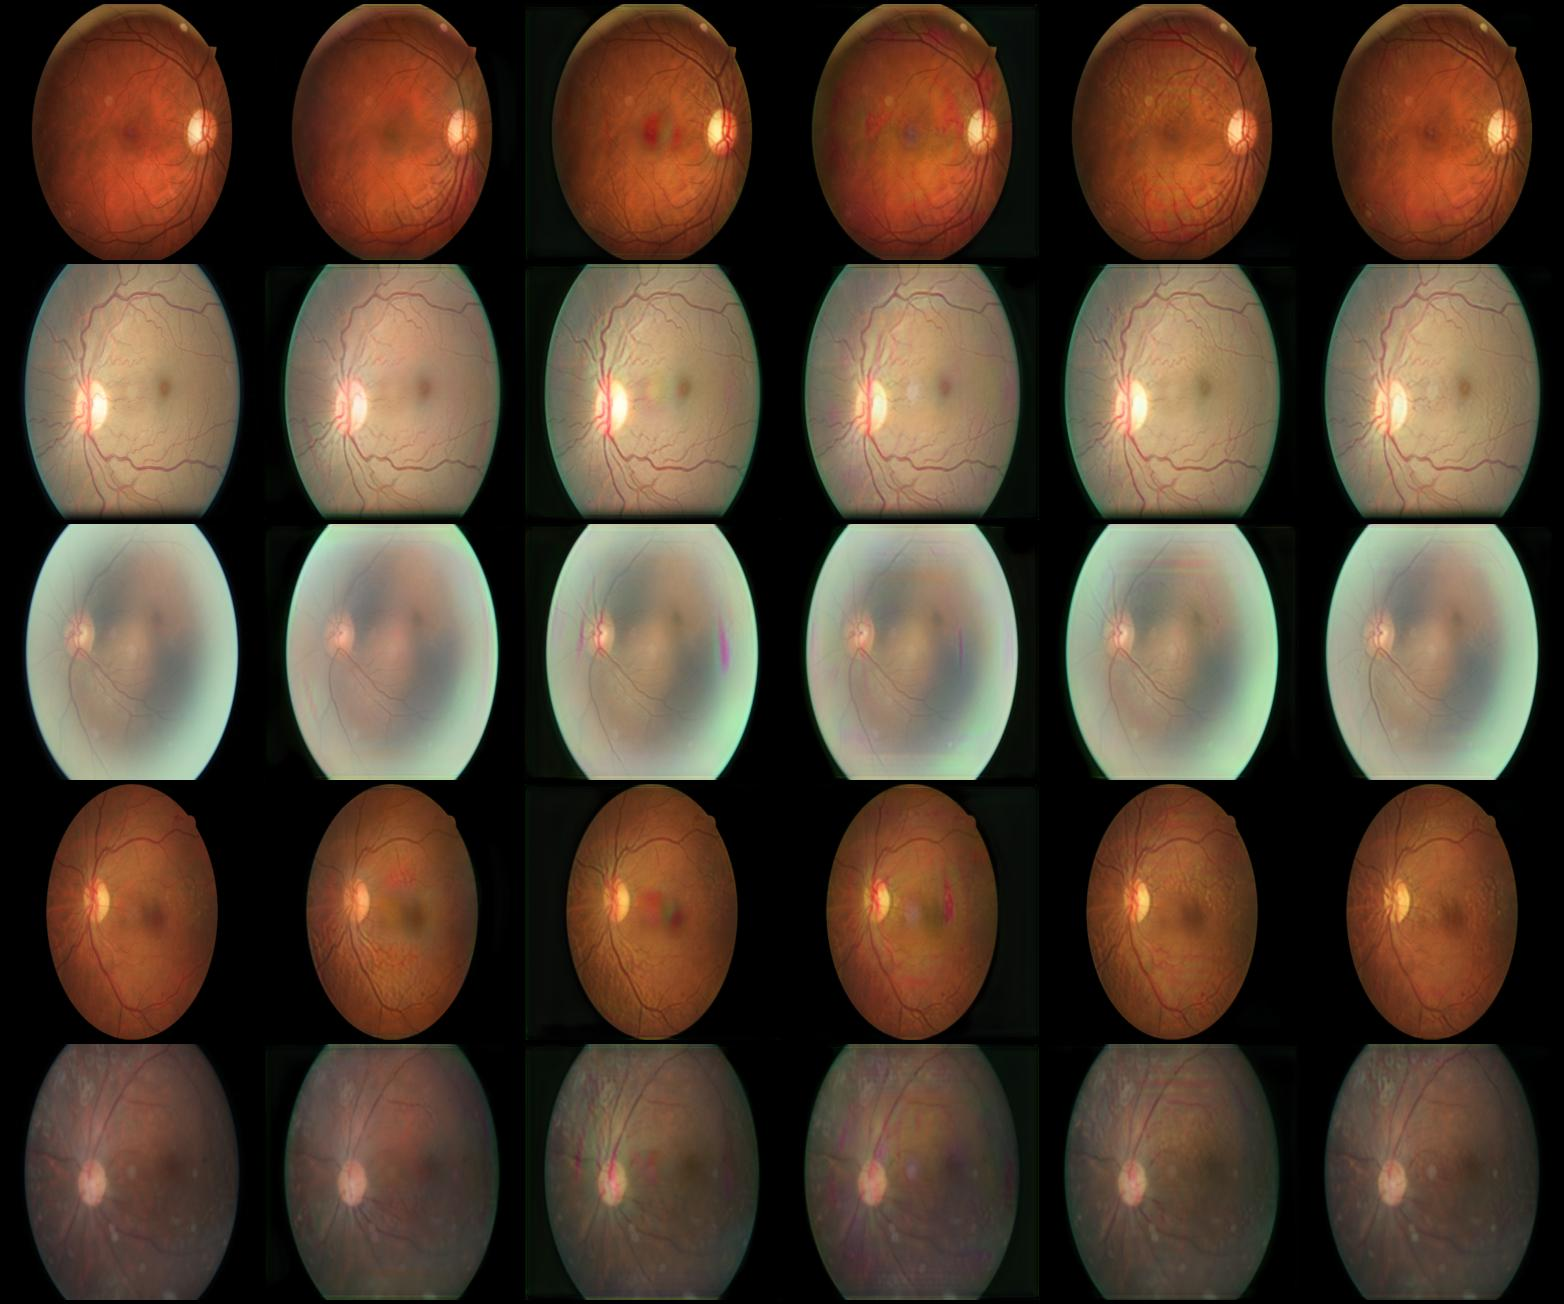


bilinear -- rows: one held-out image per grade; columns: input, then stages 0-4


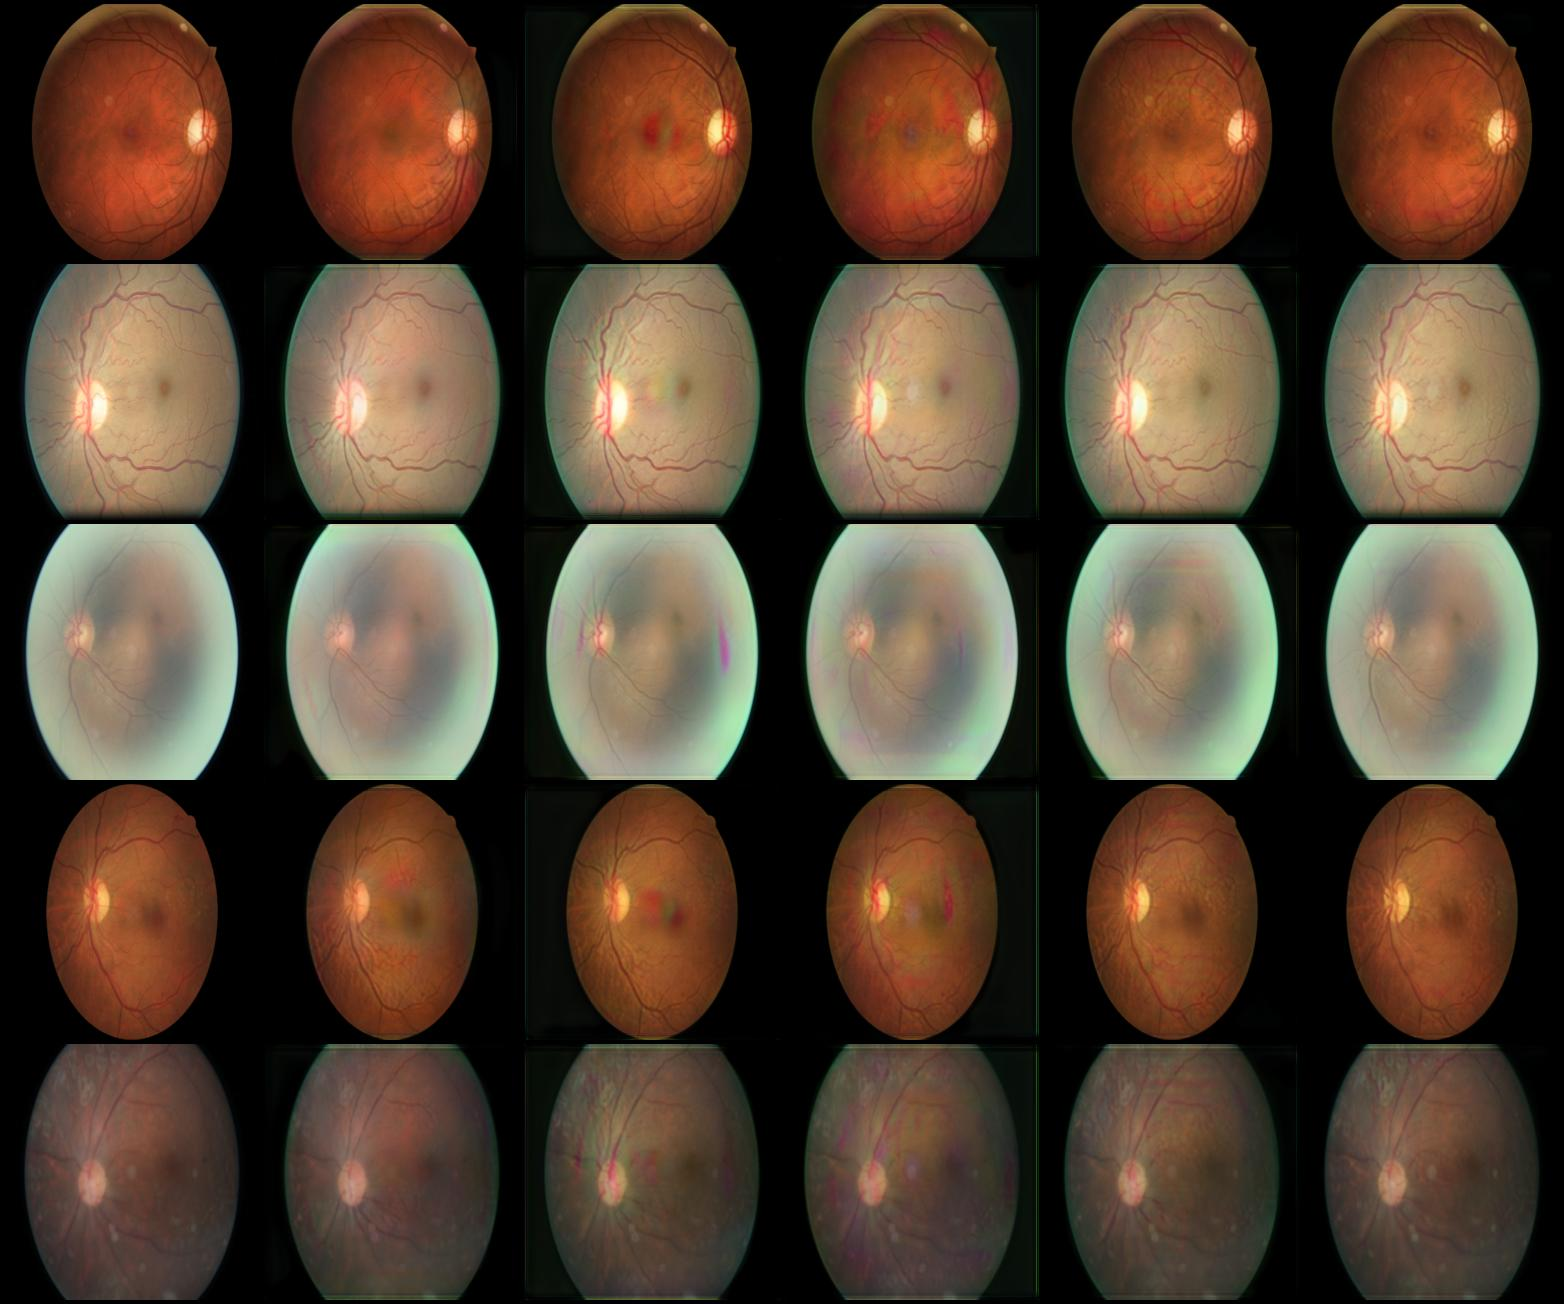


reflect -- rows: one held-out image per grade; columns: input, then stages 0-4


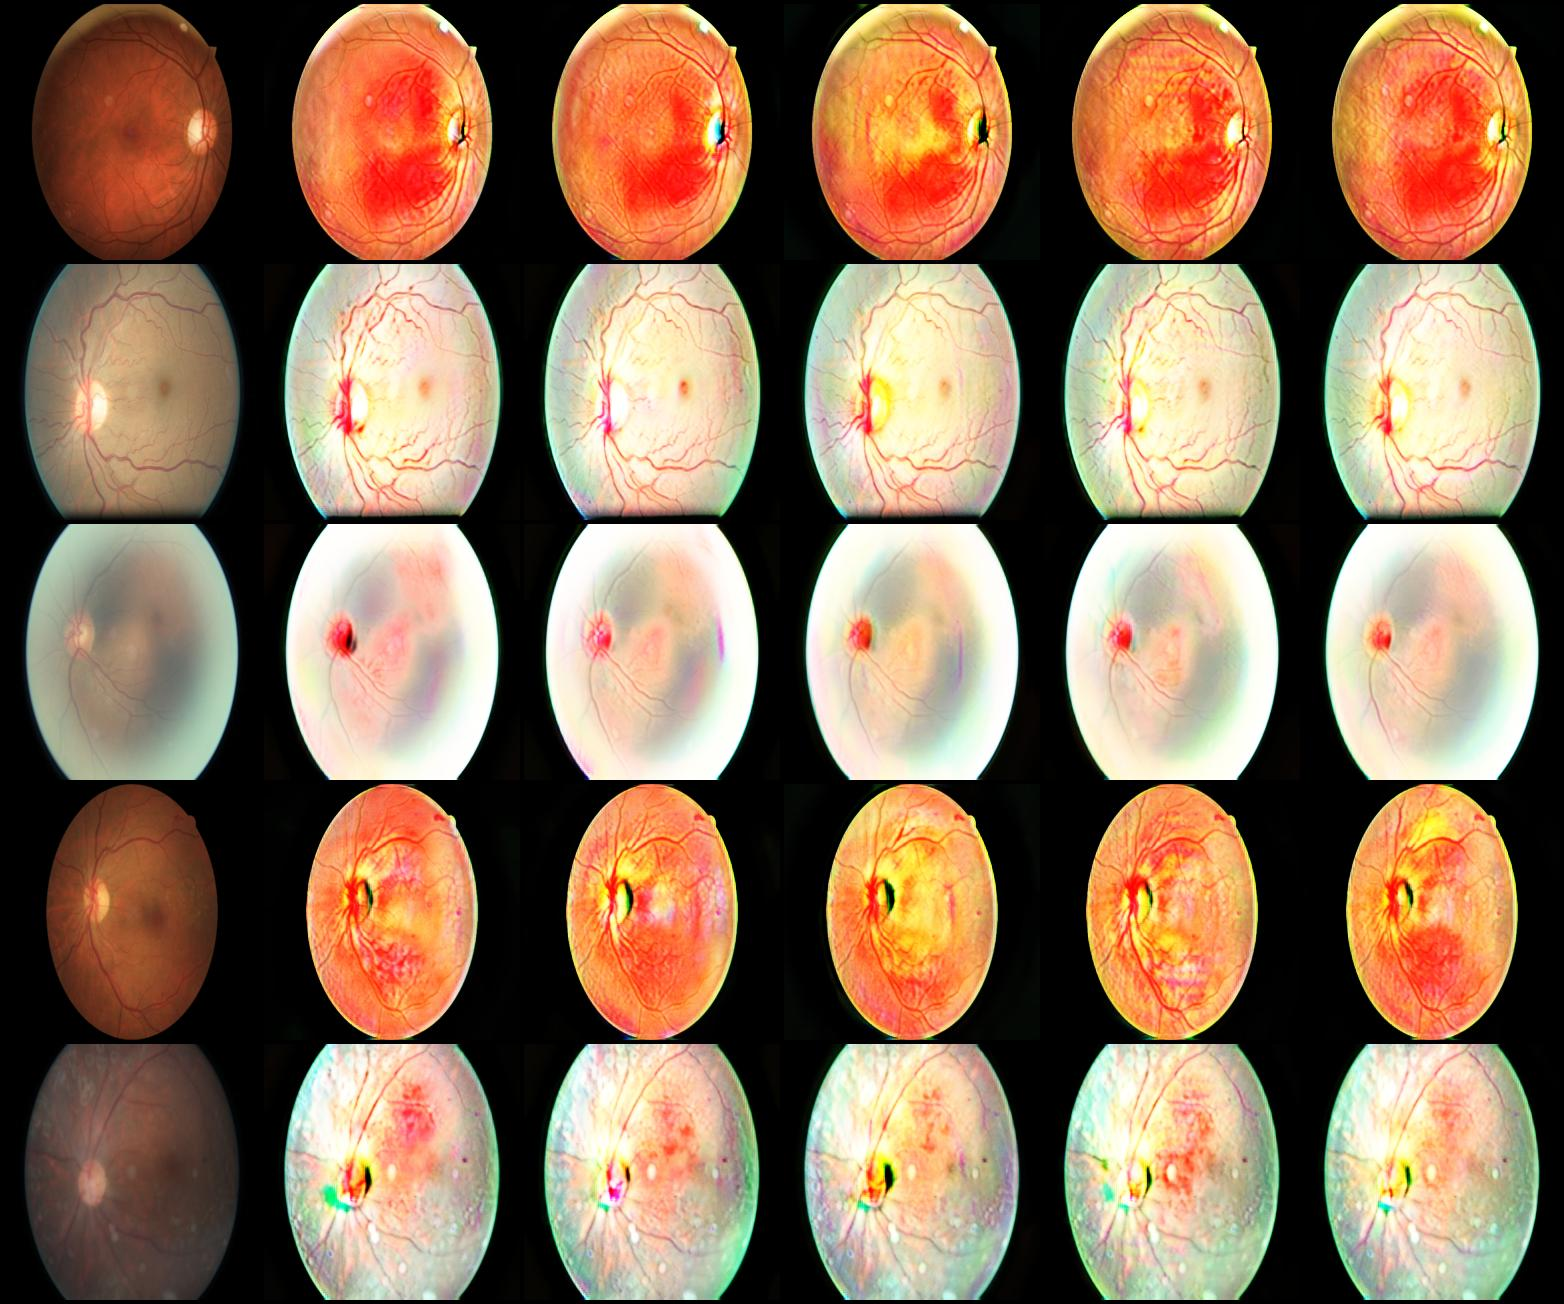


both -- rows: one held-out image per grade; columns: input, then stages 0-4


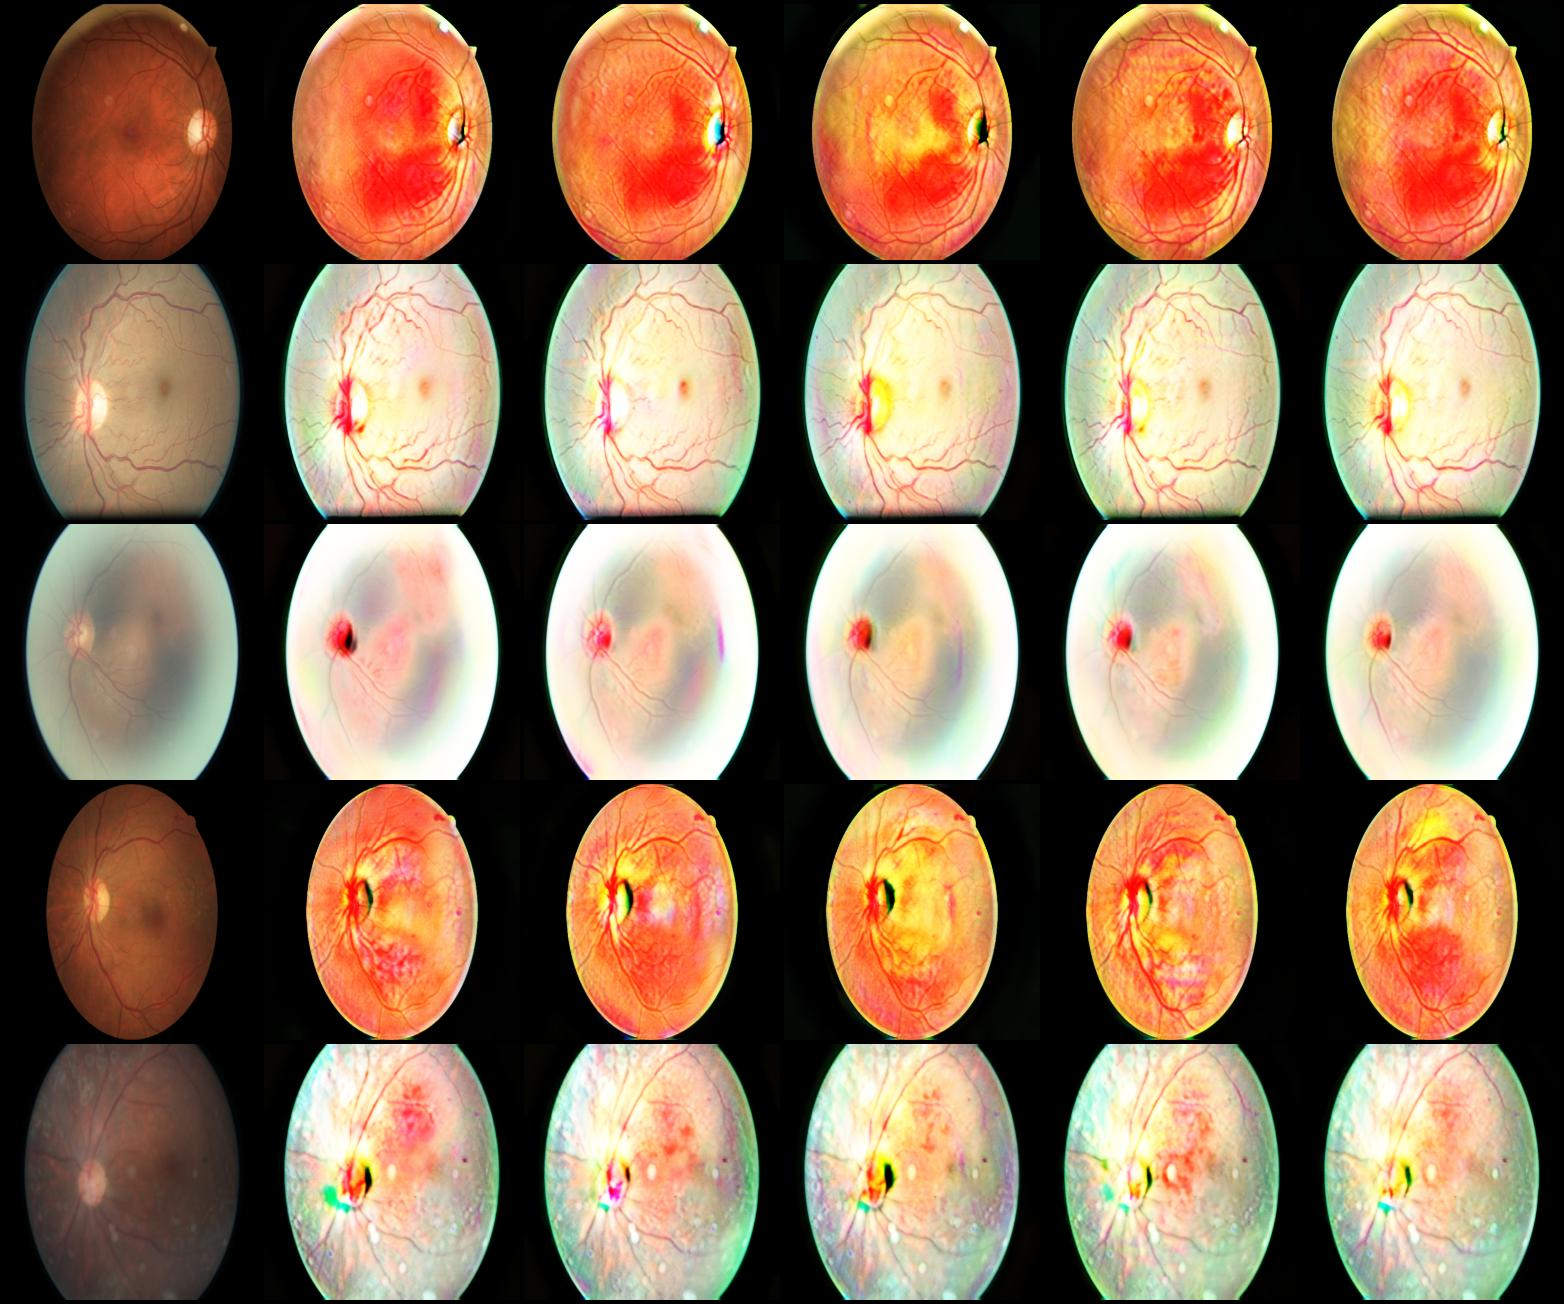

In [33]:
# Round 9 STEP 1 -- Generator layers, NO training (~5 min per variant, once; reused after). Tests A and B left the streaks
# unchanged, and the patterns sit in the same places in every image (edge bar, crosshatch, wavy bands) -- typical of the
# Generator's layers, not of its losses. Round 8's Generator is rendered three more ways, same weights:
#   bilinear  smooth up-sampling instead of nearest-neighbour (blocky up-sampling makes grid / wave patterns)
#   reflect   mirror padding at the borders instead of zeros (zero padding makes the border look different -> edge bars)
#   both
# Record only: test D trains with reflect padding regardless (a layer the Generator depends on can't be judged untrained).
from IPython.display import Image as IPImage, display
import pandas as pd
if PRETRAIN_MODE != 'tests':
    print('Skipped (PRETRAIN_MODE = "full")')
else:
    _r8_gen = os.path.join(R8_NONLONG_DIR, 'final-G.ckpt')
    _step1 = {'round 8 (as trained)': R8_CHECK_JSON}
    for _v, _fl in RENDER_VARIANTS.items():
        _out = os.path.join(TESTS_DIR, f'stage_check_r8_{_v}.json')
        _step1[_v] = _out
        if check_is_current(_out) and os.path.isfile(_out.replace('.json', '.jpg')):
            print('✓ Reusing', _out)
        else:
            print(f'\n=== round 8 Generator with {_v} ===')
            stage_check(_r8_gen, _out, _fl, grid=_out.replace('.json', '.jpg'))
    _s1 = {k: json.load(open(p)) for k, p in _step1.items() if os.path.isfile(p)}
    _rows = []
    for k, r in _s1.items():
        g = r['graders']['eyepacs']
        cm = g['confusion_requested_x_graded']
        _rows.append({'Generator': k, 'streaks (mean)': round(r['mean_streak_redness'], 4),
                      **{f'streaks {s}': round(v, 4) for s, v in r['streak_redness'].items()},
                      'tint (mean)': round(r['mean_tint'], 4),
                      'no-change: grade changed': f"{r['no_change']['grade_changed_rate']['eyepacs']:.0%}",
                      'stage ctrl (mean)': f"{g['mean_agreement']:.0%}", '0 -> graded 4': f"{cm[0][4] / max(sum(cm[0]), 1):.0%}"})
    display(pd.DataFrame(_rows))
    _base = _s1['round 8 (as trained)']['mean_streak_redness']
    _chg8 = _s1['round 8 (as trained)']['no_change']['mean_abs_change']
    print('\nSTEP 1 (record only -- test D always trains with reflect padding):')
    for v in RENDER_VARIANTS:
        r = _s1[v]
        broken = r['no_change']['mean_abs_change'] > 3 * _chg8
        print(f"  {v:9s}: streaks {r['mean_streak_redness']:.4f} ({r['mean_streak_redness'] / _base:.0%} of round 8 as trained), "
              f"no-change image change {r['no_change']['mean_abs_change']:.3f} (round 8: {_chg8:.3f})"
              + (" -> images BREAK without retraining: the Generator depends on this layer; only retraining (test D) can judge it"
                 if broken else ""))
    for k, p in _step1.items():
        _g = p.replace('.json', '.jpg')
        if os.path.isfile(_g):
            print(f'\n{k} -- rows: one held-out image per grade; columns: input, then stages 0-4')
            display(IPImage(_g, width=900))


In [34]:
# Round 9 test run TEST_RUN: round 8's training state (resume_state.pt, 80 epochs) is COPIED into this run's own folder
# (fresh runs -- E -- start from scratch instead and train to E_EPOCHS in total)
# and training continues for TEST_EPOCHS more epochs with the run's settings (round 8's folder is never written to).
# Resumes after a disconnect like the full pretraining: re-run the notebook with the same TEST_RUN. Then the stage check
# (with the no-change / redness numbers) runs on the result.
_flags = run_flags(TEST_RUN) if PRETRAIN_MODE == 'tests' else None
if PRETRAIN_MODE != 'tests':
    print('Skipped (PRETRAIN_MODE = "full")')
else:
    import shutil
    _dir = test_dir(TEST_RUN)
    os.makedirs(_dir, exist_ok=True)
    _state = os.path.join(_dir, 'resume_state.pt')
    _r8_state = os.path.join(R8_NONLONG_DIR, 'resume_state.pt')
    _r8_epochs = len(json.load(open(os.path.join(R8_NONLONG_DIR, 'nonlong_pretrain_results.json')))['loss_history'])
    _fresh = TEST_RUN in FRESH_RUNS
    _target = E_EPOCHS if _fresh else _r8_epochs + TEST_EPOCHS_FOR.get(TEST_RUN, TEST_EPOCHS)
    if _fresh and os.path.isfile(_state):
        # Back up a fresh run's state before continuing it (e.g. E 20 -> 40 epochs): resume_state.pt is overwritten every 10
        # epochs, and this copy lets a later run restart from here (before any stage signatures) instead of from scratch.
        import torch
        _done = int(torch.load(_state, map_location='cpu', weights_only=False).get('epoch', -1)) + 1
        _backup = os.path.join(_dir, f'resume_state_ep{_done}.pt')
        if 0 < _done < _target and not os.path.isfile(_backup):
            shutil.copy(_state, _backup)
            assert os.path.getsize(_backup) == os.path.getsize(_state), 'backup incomplete -- is Google Drive full?'
            print(f'✓ Backed up the {_done}-epoch state before continuing to {_target}: {_backup}')
        elif os.path.isfile(_backup):
            print(f'✓ {_done}-epoch backup already there: {_backup}')
    if _fresh and not os.path.isfile(_state):
        print(f'Test {TEST_RUN}: FRESH pretraining from scratch (no round-8 state), {_target} epochs -> {_dir}')
    elif not os.path.isfile(_state):
        assert os.path.isfile(_r8_state), f'{_r8_state} not found -- round 8\'s notebook 09 output'
        shutil.copy(_r8_state, _state)
        assert os.path.getsize(_state) == os.path.getsize(_r8_state), 'copy incomplete -- is Google Drive full?'
        print(f'✓ Copied round 8\'s training state ({_r8_epochs} epochs) -> {_state}')
    else:
        print(f'Continuing this test run\'s own state: {_state}')
    PRETRAIN_BATCH_SIZE = 16 if MODULE2_IMAGE_SIZE <= 128 else 8  # round 8's
    %cd {REPO_CODE_DIR}
    !python train_module2_nonlong_pretrain.py --image-size {MODULE2_IMAGE_SIZE} --dataset-dir "{EYEPACS_DIR}" --preset eyepacs_resized \
        --module1-cache "{EYEPACS_CACHE}" --profiles "{PROFILES_JSON}" \
        --num-epochs {_target} --samples-per-epoch 20000 --num-workers 2 \
        --batch-size {PRETRAIN_BATCH_SIZE}{_flags} \
        --save-dir "{_dir}" --sample-dir "{_dir}/samples" --resume-state "{_state}"
    assert os.path.isfile(os.path.join(_dir, 'final-G.ckpt')), (
        f'final-G.ckpt not found in {_dir}: if the output above ends with an error, fix it and re-run (it resumes); '
        'otherwise check that Google Drive is not full.')
    stage_check(os.path.join(_dir, 'final-G.ckpt'), os.path.join(_dir, 'stage_control_check.json'),
                render_flags(TEST_RUN), grid=os.path.join(_dir, 'stage_control_check.jpg'))


✓ Backed up the 60-epoch state before continuing to 80: /content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb_prefinals_r9test_E/resume_state_ep60.pt
Continuing this test run's own state: /content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb_prefinals_r9test_E/resume_state.pt
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Module 2 stage-1 pretraining on cross-sectional data
Device: cuda | dataset: /content/data/eyepacs (eyepacs_resized)

[1/4] Loading cross-sectional dataset...
  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ Loaded Module 1 cache: 13001 images, 13001/88700 labelled images covered (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r9/module1_outputs_eyepacs.pt)
✓ Cross-sectional (eyepacs_resized): 88700 images, per grade [65342, 6205, 13152, 2087, 1914]
✓ Split: 79831 train / 8869 val (grade-balanced sampling)


,run,settings,streaks (mean),streaks 0,streaks 1,streaks 2,streaks 3,streaks 4,tint (mean),tint at stage 0,no-change: image change,no-change: grade changed,stage ctrl (mean),0 -> graded 4
0,round 8,round 8 pretrained (80 epochs),0.0108,0.0126,0.0114,0.0118,0.0102,0.0081,0.0003,0.0013,0.0167,42%,29%,40%
1,A,identity every step + DiffAugment,0.0112,0.0087,0.0123,0.0110,0.0131,0.0106,0.0037,0.0163,0.0165,36%,30%,20%
2,B,identity every step + DiffAugment + biomarker ...,0.0113,0.0090,0.0118,0.0123,0.0128,0.0106,0.0074,0.0252,0.0190,38%,30%,16%
3,D,"A + mirror (reflect) padding, 15 epochs",0.0132,0.0115,0.0141,0.0117,0.0155,0.0132,0.0185,0.0542,0.0349,40%,26%,22%



Round 8: streaks 0.0108 | tint 0.0003 | no-change grade changed 42% | stage control 29%
  A (identity every step + DiffAugment): streaks 0.0112 (103% of round 8) | tint 0.0037 | no-change grade changed 36% (image change 0.016) | stage control 30% -> does not fix them
  B (identity every step + DiffAugment + biomarker loss off): streaks 0.0113 (105% of round 8) | tint 0.0074 | no-change grade changed 38% (image change 0.019) | stage control 30% -> does not fix them
  D (A + mirror (reflect) padding, 15 epochs): streaks 0.0132 (122% of round 8) | tint 0.0185 | no-change grade changed 40% (image change 0.035) | stage control 26% -> does not fix them

VERDICT:
  NO WINNER: no finished run (A, B, D) halves round 8's streaks without making the no-change test worse (best: A, 103% of round 8's streaks).
  Neither the loss changes (A, B) nor reflect padding (D) reduce the streaks enough when continuing from
  round 8: they are most likely baked into round 8's weights. The fresh start from scra

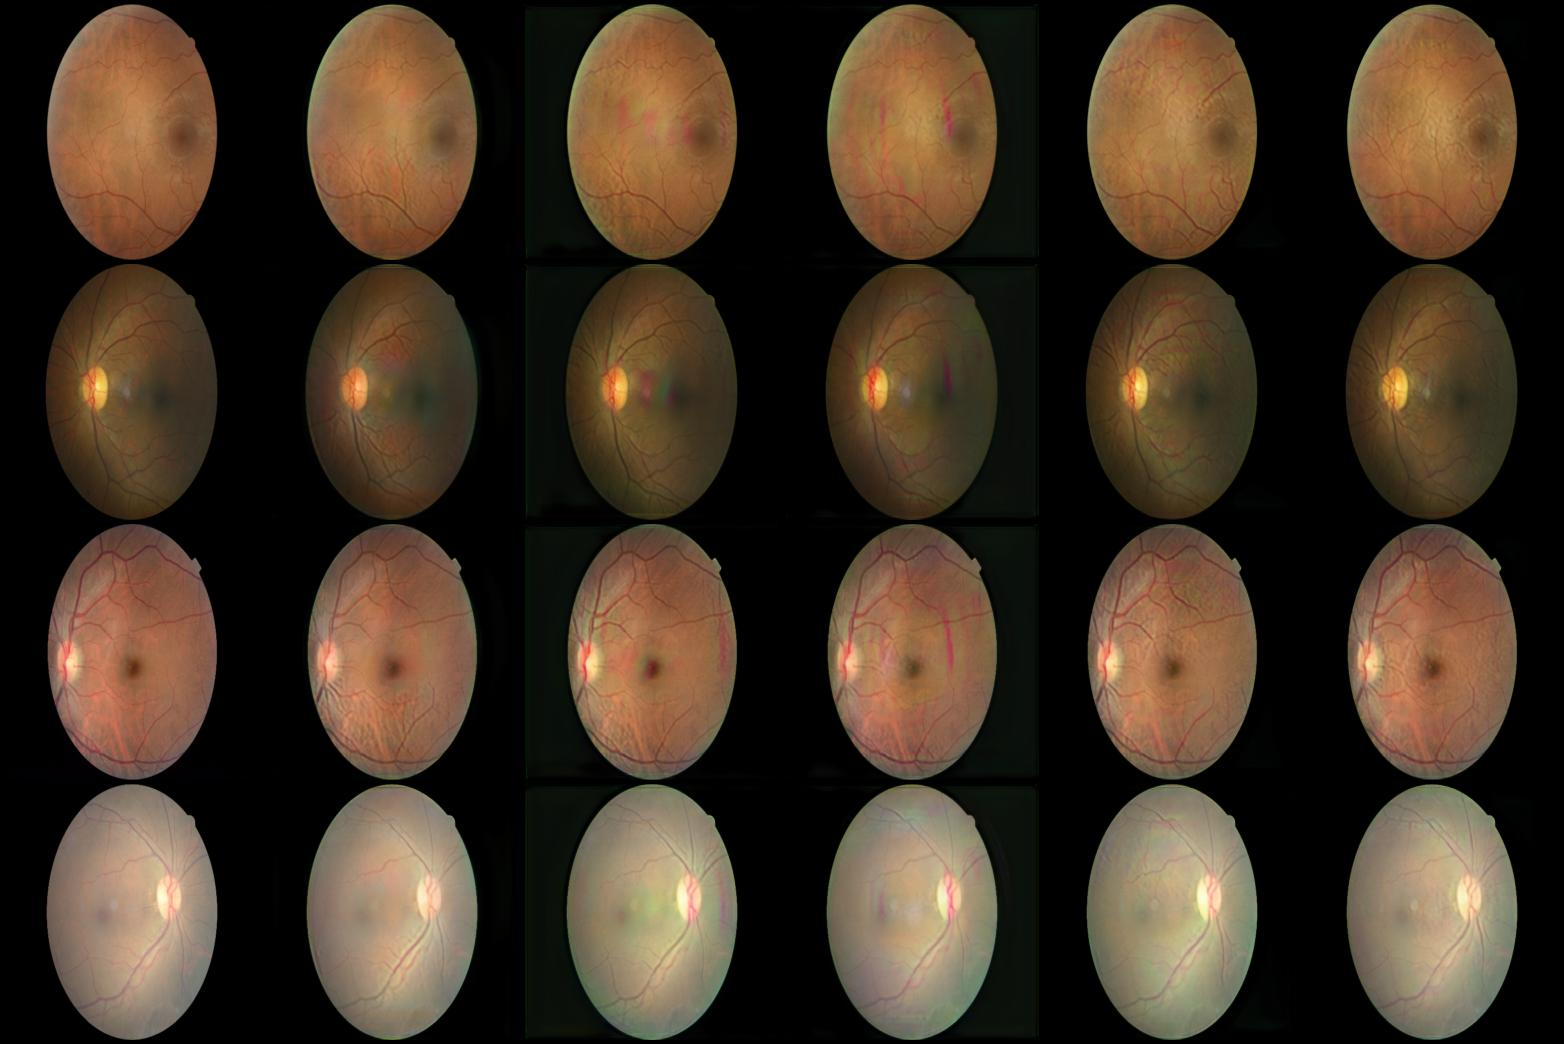


A: epoch_90.jpg


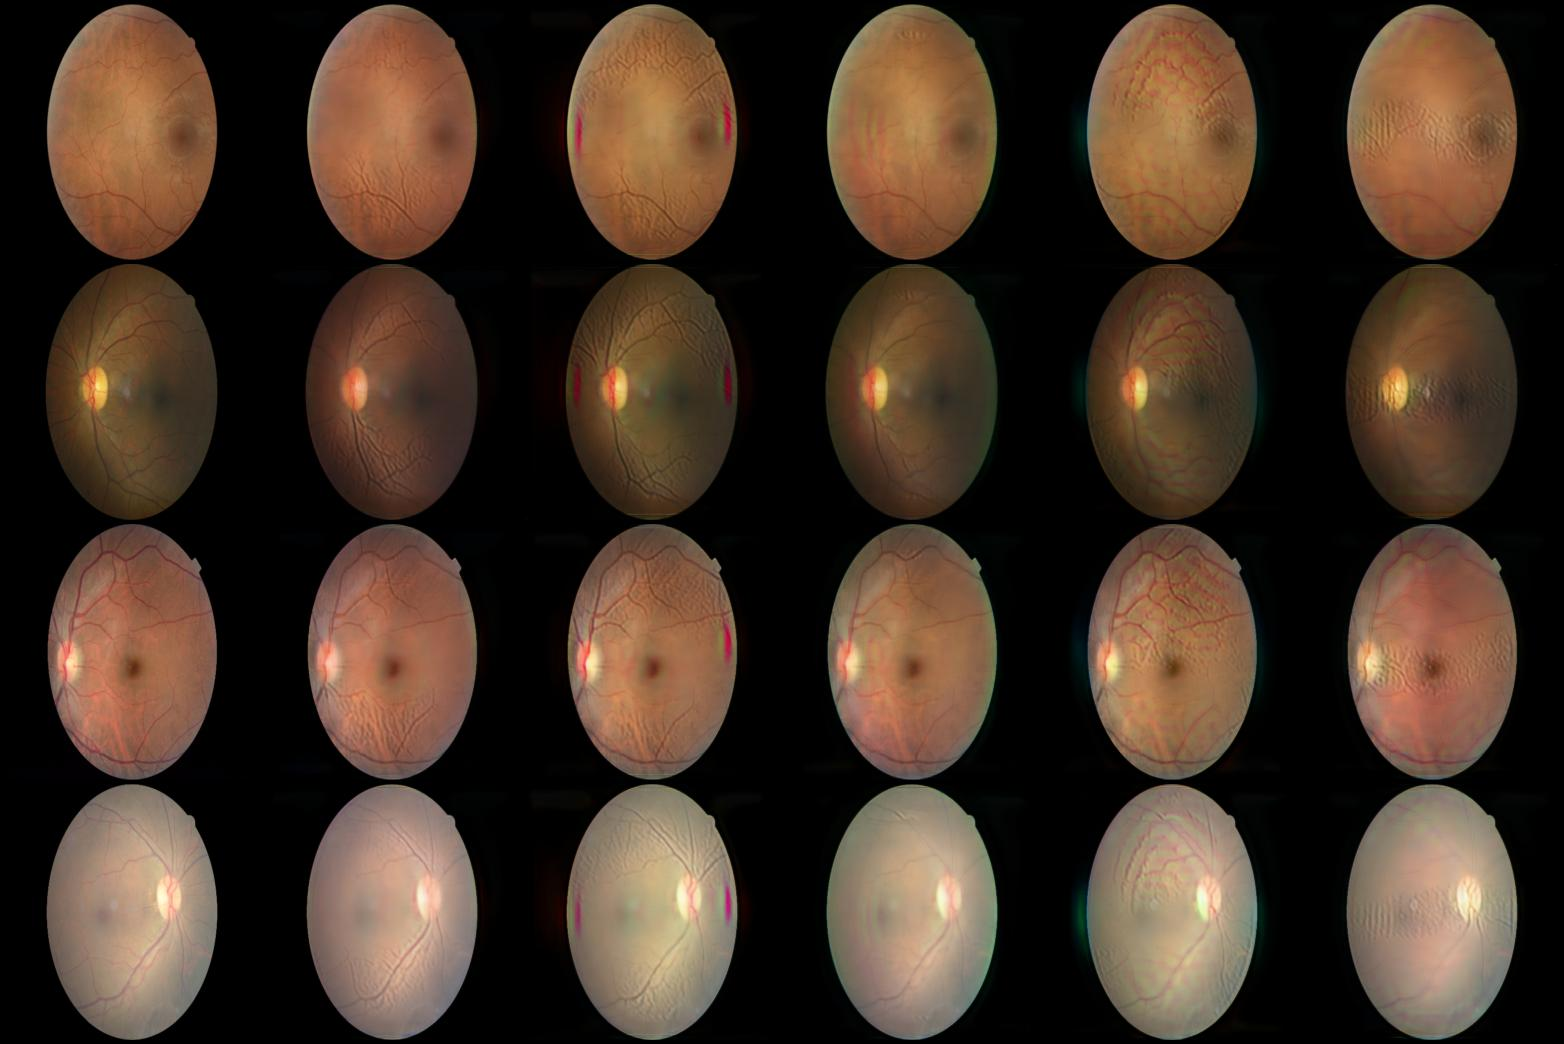


B: epoch_90.jpg


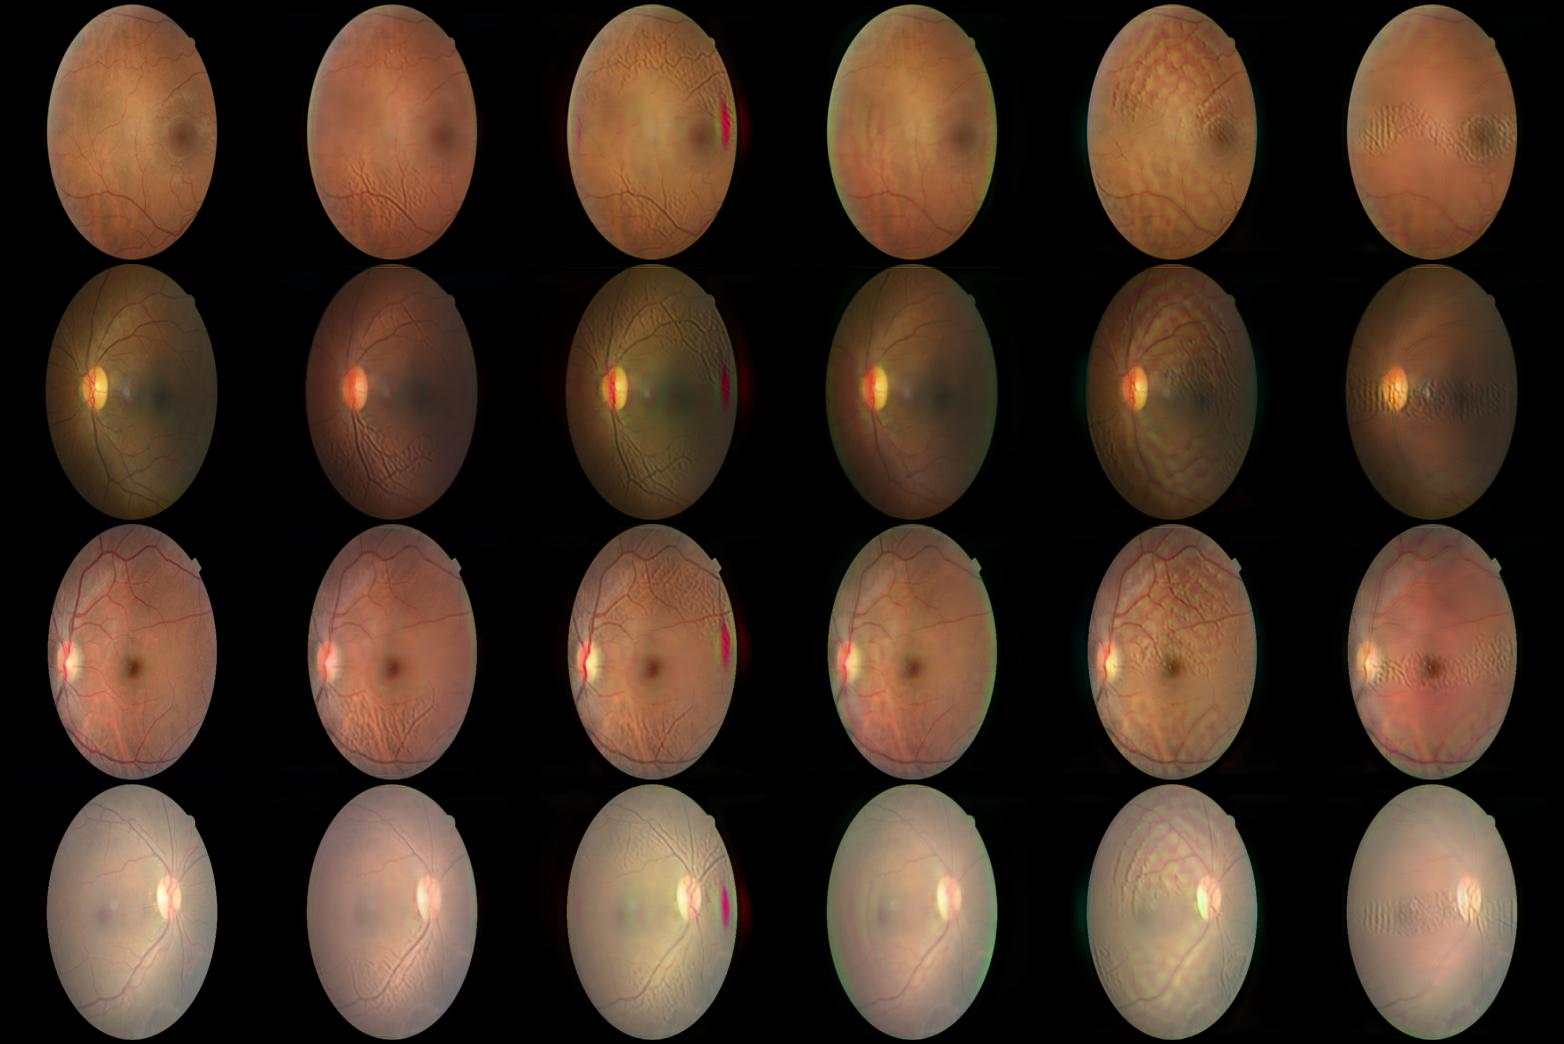


D: epoch_95.jpg


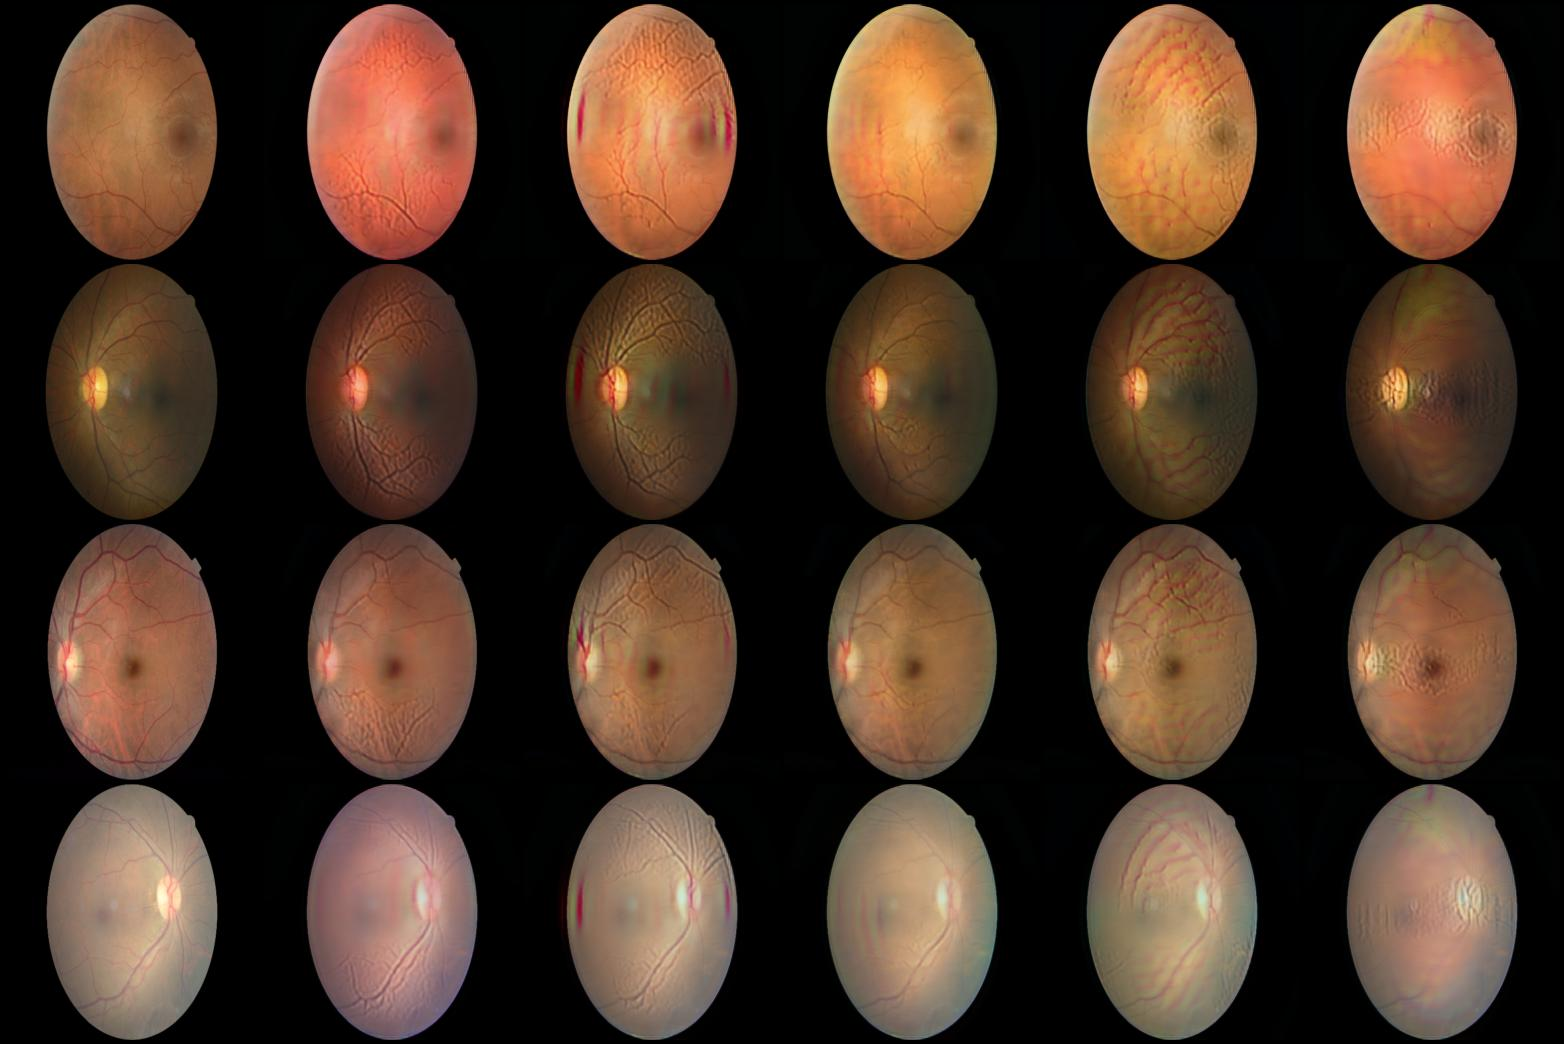


=== round 8 at 80 epochs (final-G.ckpt) -- the like-for-like reference for test E ===
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ Loaded Module 1 cache: 13001 images, 13001/88700 labelled images covered (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r9/module1_outputs_eyepacs.pt)
✓ Cross-sectional (eyepacs_resized): 88700 images, per grade [65342, 6205, 13152, 2087, 1914]
200 held-out real images (up to 40 per grade) x 5 requested stages
✓ Sample grid: /content/drive/MyDrive/Thesis_Datasets/module2_runs/round9_pretrain_tests/stage_check_r8_ep80.jpg
Image checks (inside the retina, 0-1 scale; compare between runs):
  redness added per requested stage: 0: 0.0085  1: 0.0039  2: 0.0051  3: 0.0021  4: 0.0016  | mean 0.0042
  -> local streaks:                  0: 0.0126  1: 0.0114  2: 0.0118  3: 0.0102  4: 0.0081  | mean 0.0108
  

,run,settings,strong-streak area,disc darkening,tint (mean),tint at stage 0,no-change: image change,no-change: grade changed,stage ctrl (mean),0 -> graded 4,streaks (mean)
0,round 8 @ 80 ep,"round 8 settings, 80 epochs",0.0118,0.0166,0.0003,0.0013,0.0167,42%,29%,40%,0.0108
1,E @ 40 ep,"E, identity weight 5",0.0322,0.0405,0.0379,0.0769,0.0356,41%,23%,27%,0.0145
2,E @ 80 ep,"E, identity weight 20 from epoch 41",0.0056,0.0223,0.0088,0.0248,0.0217,40%,22%,35%,0.0101



TEST E at 80 epochs vs round 8 at 80 epochs:
  strong-streak area 0.0056 vs 0.0118 -> OK (at most half)
  disc darkening     0.0223 vs 0.0166 -> OK (at most 1.5x)
  no-change change   0.0217 vs 0.0167 -> OK (at most 1.5x)
  (tint 0.0088 vs 0.0003 | stage control 22% vs 29%)
  stronger identity loss (E @ 40 -> E @ 80): disc darkening 0.0405 -> 0.0223, no-change change 0.0356 -> 0.0217, tint at stage 0 0.0769 -> 0.0248
TEST E VERDICT:
  E WORKS at 80 epochs: test E's Generator IS round 9's pretrained Generator (folder nonlong_pretrain..._r9test_E).
  Report back: notebooks 06/08/10 are pointed at it next (with reflect padding).

round 8 @ 80 epochs -- rows: one held-out image per grade; columns: input, then stages 0-4


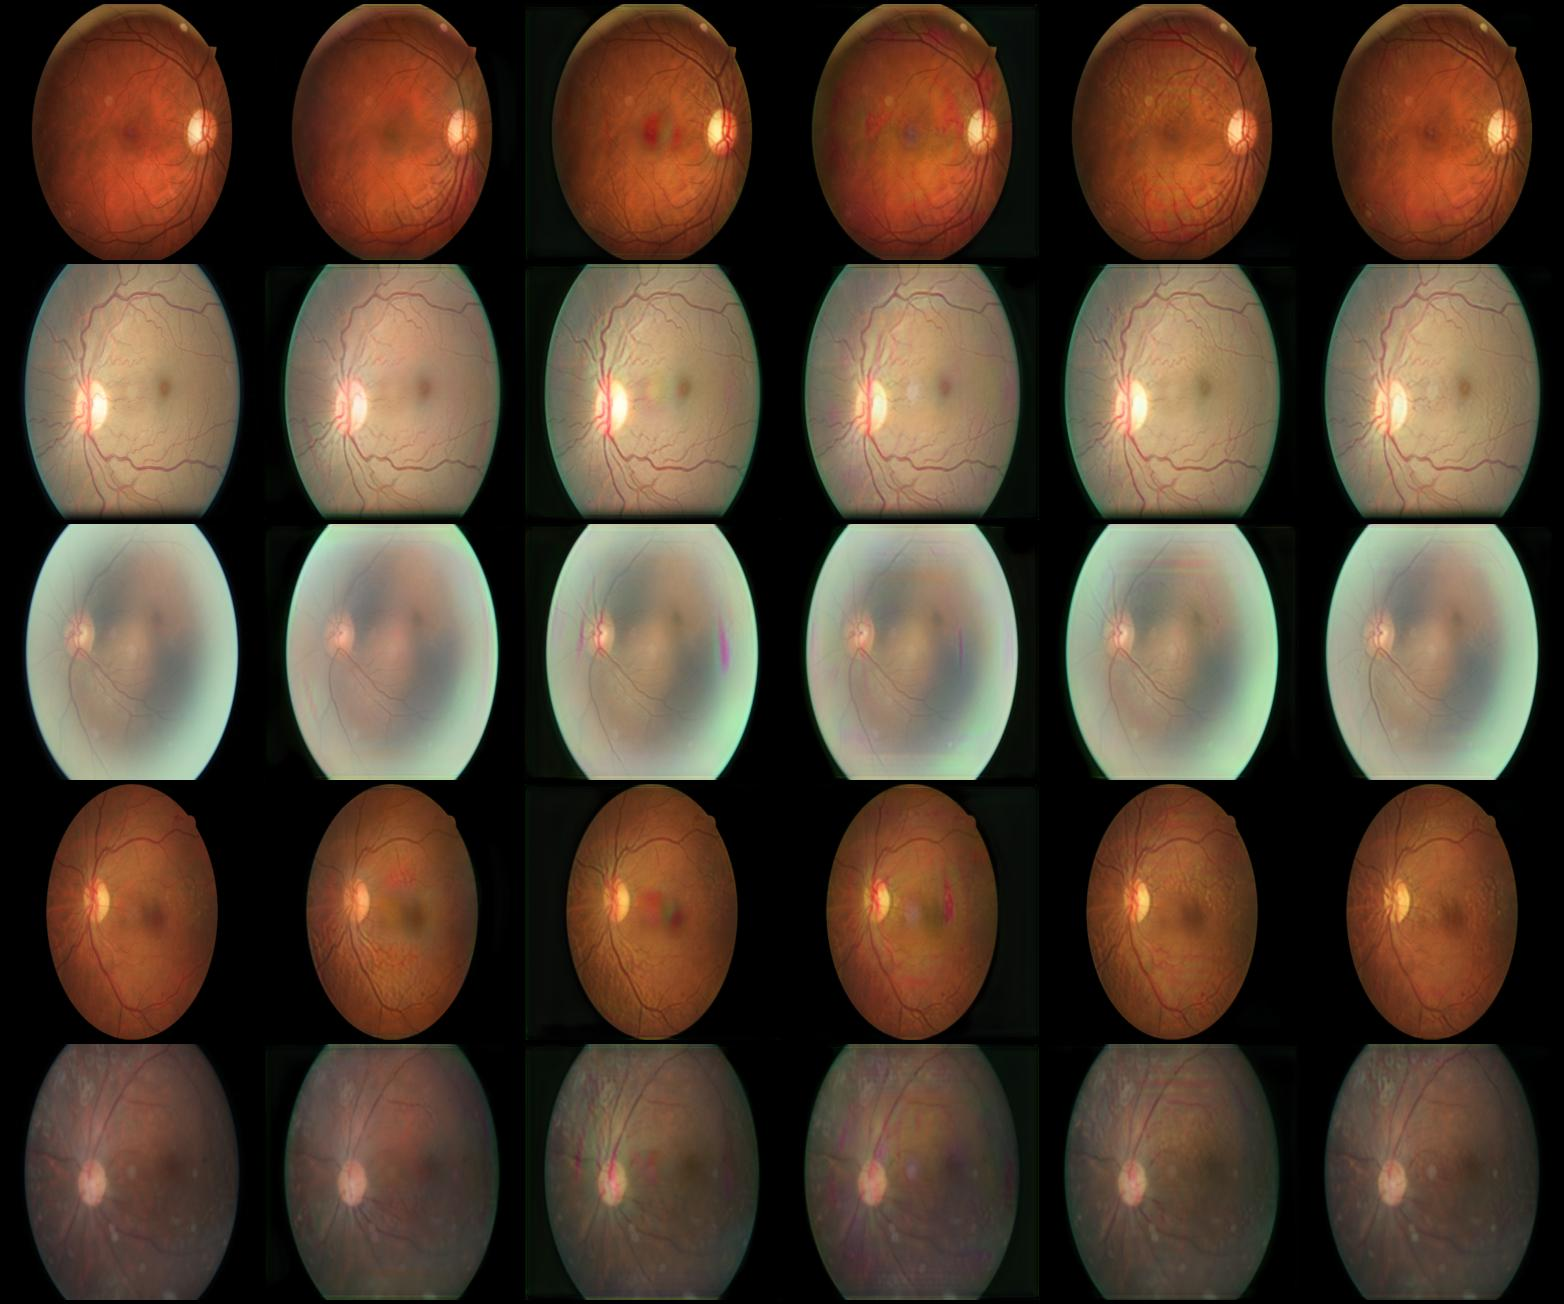


E @ 80 epochs -- rows: one held-out image per grade; columns: input, then stages 0-4


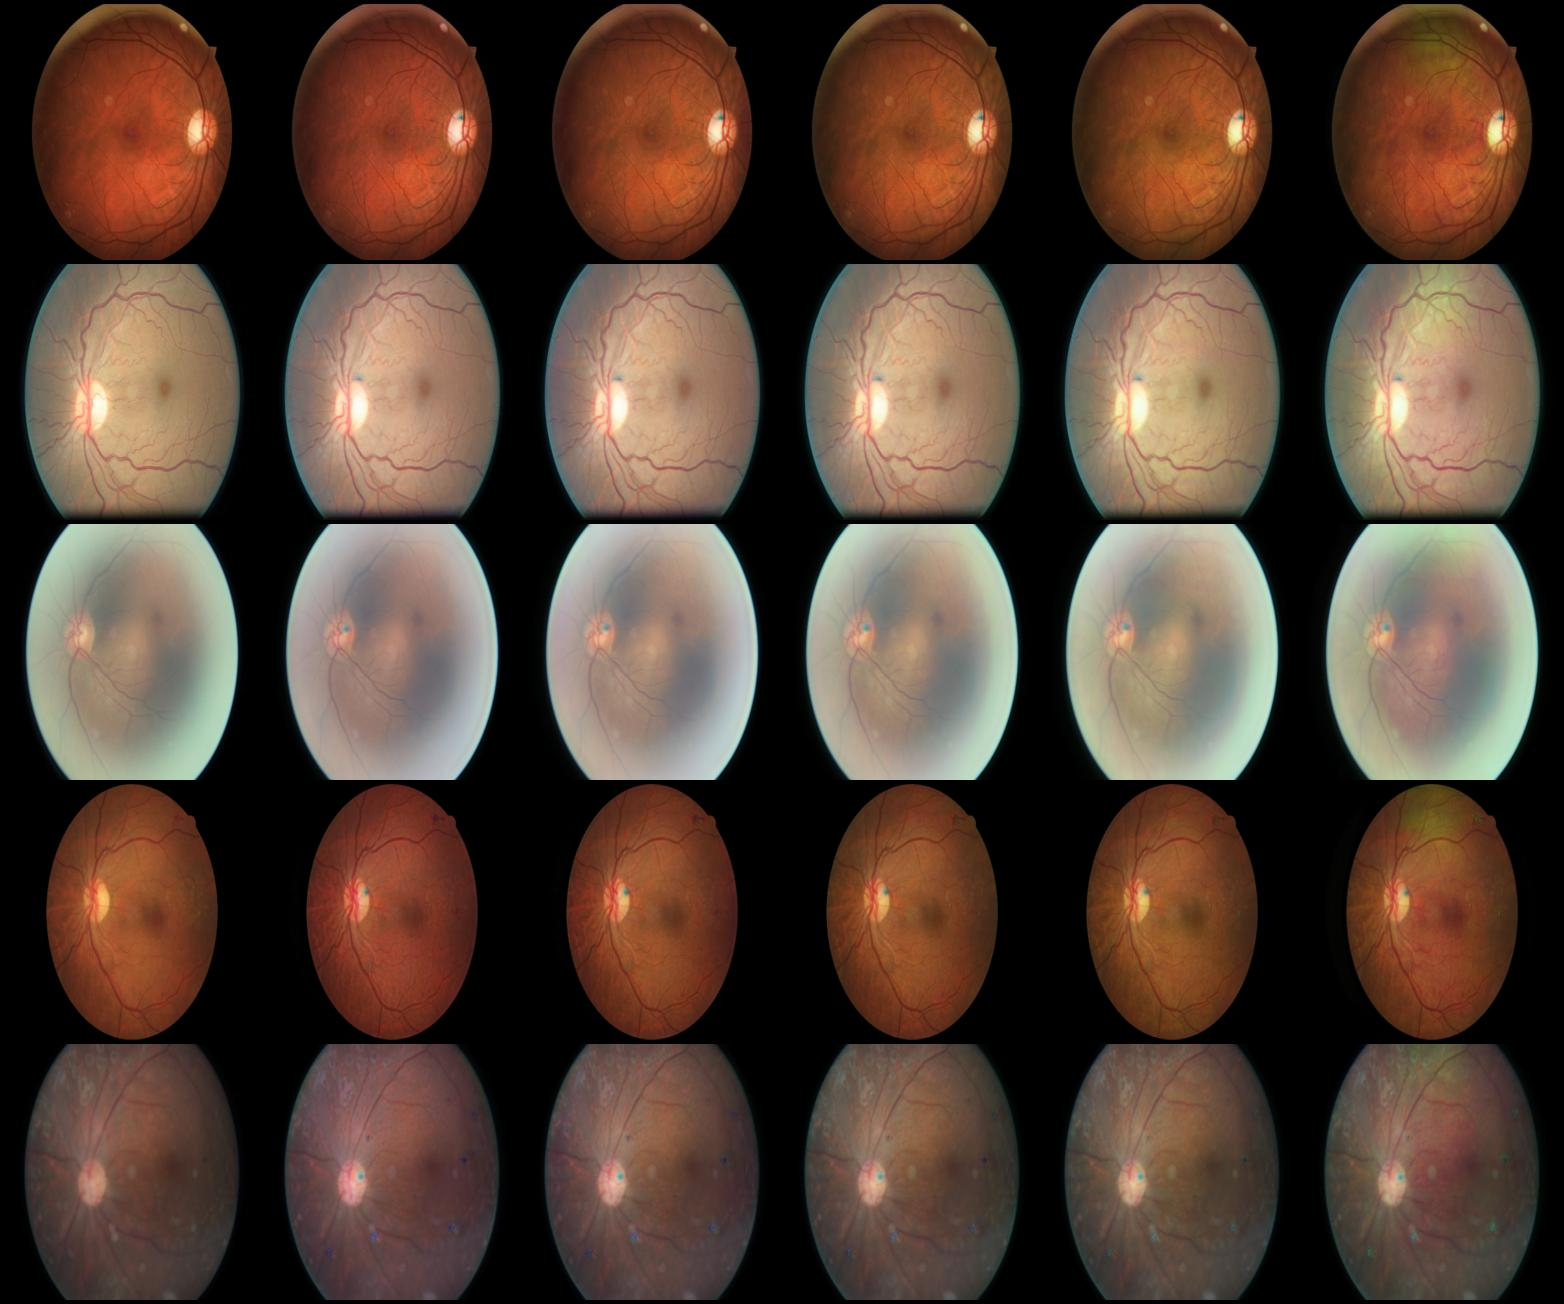

In [35]:
# Round 9 comparison + VERDICT: every finished test run vs round 8, on the same held-out EyePACS images (EyePACS grader).
#   streaks      LOCAL red added inside the retina (each image's own average colour shift removed), averaged over the
#                requested stages -- the red streaks / blotches (lower = fewer). Decides the verdict.
#   tint         whole-image colour shift towards red (e.g. a pinker eye); reported and flagged, not the verdict
#   no-change    own stage requested: mean change of the image, and how often the EyePACS grade changes (both -> 0)
#   stage ctrl   requested stage read as that stage (chance 20 %); "0 -> graded 4" = stage-0 requests read as grade 4
# A run FIXES the streaks if its streak number is at most REDNESS_FIX x round 8's AND its no-change grade-change rate is
# not higher than round 8's AND its no-change image change is at most 2x round 8's (the images are intact). Winner = the fixing run with the fewest streaks; A is kept if within 10 % (fewest changes).
# Check JSONs from before the tint / streak split are recomputed first (~5 min each).
REDNESS_FIX = 0.5
import pandas as pd
from IPython.display import Image as IPImage, display
if PRETRAIN_MODE != 'tests':
    print('Skipped (PRETRAIN_MODE = "full")')
else:
    _runs = {'round 8': os.path.join(TESTS_DIR, 'stage_check_r8.json')}
    _CONT = [k for k in TEST_SETTINGS if k not in FRESH_RUNS]  # runs that continue round 8 (E has its own block below)
    _runs.update({k: os.path.join(test_dir(k), 'stage_control_check.json') for k in _CONT})
    _gens = {'round 8': os.path.join(R8_NONLONG_DIR, 'final-G.ckpt')}
    _gens.update({k: os.path.join(test_dir(k), 'final-G.ckpt') for k in _CONT})
    for _k, _p in _runs.items():  # older checks without the tint / streak split -> redo them on the same Generator
        if os.path.isfile(_p) and not check_is_current(_p) and os.path.isfile(_gens[_k]):
            print(f'↻ Re-checking {_k} with the tint / streak split ({_gens[_k]})')
            stage_check(_gens[_k], _p, render_flags(_k) or '' if _k in TEST_SETTINGS else '')
    _res = {k: json.load(open(p)) for k, p in _runs.items() if os.path.isfile(p)}
    _planned = ['A', 'B', 'D']  # C is optional
    _missing = [k for k in _planned if k not in _res]
    def _label(name):
        return TEST_SETTINGS[name]['label'] if name in TEST_SETTINGS else 'round 8 pretrained (80 epochs)'
    def _row(name, r):
        g = r['graders']['eyepacs']
        cm = g['confusion_requested_x_graded']
        return {'run': name, 'settings': _label(name),
                'streaks (mean)': round(r['mean_streak_redness'], 4),
                **{f'streaks {k}': round(v, 4) for k, v in r['streak_redness'].items()},
                'tint (mean)': round(r['mean_tint'], 4), 'tint at stage 0': round(r['tint']['0'], 4),
                'no-change: image change': round(r['no_change']['mean_abs_change'], 4),
                'no-change: grade changed': f"{r['no_change']['grade_changed_rate']['eyepacs']:.0%}",
                'stage ctrl (mean)': f"{g['mean_agreement']:.0%}",
                '0 -> graded 4': f"{cm[0][4] / max(sum(cm[0]), 1):.0%}"}
    if 'round 8' not in _res:
        print('⚠ Round 8 baseline check missing -- run the round-8 baseline cell above first.')
    else:
        _table = pd.DataFrame([_row(k, r) for k, r in _res.items()])
        display(_table)
        _table.to_csv(os.path.join(TESTS_DIR, 'round9_pretrain_tests.csv'), index=False)
        r8 = _res['round 8']
        red8, flip8, tint8 = r8['mean_streak_redness'], r8['no_change']['grade_changed_rate']['eyepacs'], r8['mean_tint']
        chg8 = r8['no_change']['mean_abs_change']
        def _fixes(k):
            r = _res[k]
            return (r['mean_streak_redness'] <= REDNESS_FIX * red8
                    and r['no_change']['grade_changed_rate']['eyepacs'] <= flip8 + 1e-9
                    and r['no_change']['mean_abs_change'] <= 2 * chg8)  # images recovered (D starts from a broken state)
        print(f"\nRound 8: streaks {red8:.4f} | tint {tint8:.4f} | no-change grade changed {flip8:.0%} | "
              f"stage control {r8['graders']['eyepacs']['mean_agreement']:.0%}")
        for k in _CONT:
            if k in _res:
                r = _res[k]
                print(f"  {k} ({_label(k)}): streaks {r['mean_streak_redness']:.4f} "
                      f"({r['mean_streak_redness'] / red8:.0%} of round 8) | tint {r['mean_tint']:.4f} | no-change grade changed "
                      f"{r['no_change']['grade_changed_rate']['eyepacs']:.0%} (image change {r['no_change']['mean_abs_change']:.3f}) | stage control "
                      f"{r['graders']['eyepacs']['mean_agreement']:.0%} -> {'FIXES the streaks' if _fixes(k) else 'does not fix them'}")
        print('\nVERDICT:')
        done = [k for k in ('A', 'B', 'D') if k in _res]
        fixing = [k for k in done if _fixes(k)]
        if not done:
            print('  No test run finished yet -- run this notebook with TEST_RUN = "A" (then "B").')
        elif not fixing:
            best = min(done, key=lambda k: _res[k]['mean_streak_redness'])
            print(f"  NO WINNER: no finished run ({', '.join(done)}) halves round 8's streaks without making the no-change "
                  f"test worse (best: {best}, {_res[best]['mean_streak_redness'] / red8:.0%} of round 8's streaks).")
            if 'C' in _res and _fixes('C'):
                print('  Note: the control C (no changes) DOES halve the streaks -- extra training alone helps, the changes do not.')
            if _missing:
                print(f"  Still to run: {', '.join(_missing)} -- run it before deciding (TEST_RUN = '{_missing[0]}').")
            else:
                print("  Neither the loss changes (A, B) nor reflect padding (D) reduce the streaks enough when continuing from")
                print("  round 8: they are most likely baked into round 8's weights. The fresh start from scratch is test E --")
                print("  see the TEST E VERDICT below (run it with TEST_RUN = 'E' if it is not there yet).")
        else:
            win = min(fixing, key=lambda k: _res[k]['mean_streak_redness'])
            if win != 'A' and 'A' in fixing and _res['A']['mean_streak_redness'] <= 1.1 * _res[win]['mean_streak_redness']:
                win = 'A'  # within 10 %: keep the run with the fewest changes
            w = _res[win]
            print(f"  WINNER: {win} ({_label(win)}) -- streaks {w['mean_streak_redness'] / red8:.0%} of round 8's, "
                  f"no-change grade changed {w['no_change']['grade_changed_rate']['eyepacs']:.0%} (round 8: {flip8:.0%}).")
            if win == 'D':
                print("  Zero padding was a cause: the full pretraining (and later notebooks 06/08/10) uses reflect padding "
                      "(--g-padding reflect). D trained 15 epochs vs A/B's 10 -- noted, but A/B did not move at all.")
            elif win == 'B':
                print('  The biomarker regressor was a main source of the red: B (biomarker loss off) beat A clearly.')
            if 'C' in _res and _fixes('C'):
                print('  ⚠ BUT the control C (no changes) also fixes it: extra training alone helped, so the gain is not '
                      'clearly from the changes. Still use the winner (it does at least as well), and say so in the write-up.')
            if w['mean_tint'] > 2 * max(tint8, 1e-4):
                print(f"  ⚠ The winner tints the whole eye redder ({w['mean_tint']:.4f} vs round 8's {tint8:.4f}): check the "
                      'sample grids for a pinker / darker eye -- notebook 06\'s colour match corrects a uniform tint, not streaks.')
            w8 = r8['graders']['eyepacs']['mean_agreement']
            if w['graders']['eyepacs']['mean_agreement'] < w8:
                print(f"  Stage control fell ({w8:.0%} -> {w['graders']['eyepacs']['mean_agreement']:.0%}): expected if the "
                      'streaks were what moved the grade in round 8 -- fine-tuning (notebook 06) is where grade control is judged.')
            if _missing:
                print(f"  Provisional: {', '.join(_missing)} not run yet.")
            print(f"  NEXT: look at the sample grids below for streaks, then set PRETRAIN_MODE = 'full' and FULL_RUN = '{win}' "
                  'in the round-9 settings cell and Run all (fresh 80-epoch pretraining, ~19 h, resumes after a disconnect).')
            with open(os.path.join(TESTS_DIR, 'verdict.json'), 'w') as f:
                json.dump({'winner': win, 'settings': _label(win), 'flags': run_flags(win),
                           'streaks_vs_round8': w['mean_streak_redness'] / red8, 'runs': list(_res)}, f, indent=2)
        # Last training-sample grid of each run (rows: held-out images; columns: input, then stages 0-4)
        for k, d in [('round 8', R8_NONLONG_DIR)] + [(k, test_dir(k)) for k in _CONT if k in _res]:
            _s = sorted(glob.glob(f'{d}/samples/epoch_*.jpg'), key=lambda p: int(p.split('_')[-1].split('.')[0]))
            if _s:
                print(f'\n{k}: {os.path.basename(_s[-1])}')
                display(IPImage(_s[-1], width=900))

# ---- TEST E (fresh pretraining from scratch) vs round 8 at the SAME number of epochs ----
# Round 8 saved a Generator every 10 epochs ({N}-G.ckpt), so E at N epochs is compared with round 8's own N-epoch snapshot.
# Targeted numbers (the plain streak number also counts mild mottling and spots, so it misled at 20 / 40 epochs):
#   strong-streak area  share of the retina with a vivid local red / magenta jump -- the bars
#   disc darkening      how much the optic disc (brightest 1 % of the input) gets darker -- the dark disc spot
# E WORKS if its strong-streak area is at most half of round 8's, its disc darkening at most 1.5x round 8's, and its
# no-change image change at most 1.5x round 8's (the eye is kept when its own grade is asked for).
_e_dir = test_dir('E')
_e_check = os.path.join(_e_dir, 'stage_control_check.json')
_e_res_json = os.path.join(_e_dir, 'nonlong_pretrain_results.json')
if PRETRAIN_MODE == 'tests' and os.path.isfile(_e_check) and os.path.isfile(_e_res_json):
    _n = len(json.load(open(_e_res_json))['loss_history'])
    _r8_ckpt = os.path.join(R8_NONLONG_DIR, 'final-G.ckpt' if _n >= 80 else f'{_n}-G.ckpt')
    _r8n_json = (os.path.join(TESTS_DIR, 'stage_check_r8_ep80.json') if _n >= 80
                 else os.path.join(TESTS_DIR, f'stage_check_r8_ep{_n}.json'))
    if not os.path.isfile(_r8_ckpt):
        print(f'\n⚠ Test E has {_n} epochs but round 8 has no {_n}-epoch snapshot ({_r8_ckpt}); round 8 saved one every 10 '
              'epochs -- set E_EPOCHS to a multiple of 10.')
    else:
        if not (check_has_targeted(_r8n_json) and os.path.isfile(_r8n_json.replace('.json', '.jpg'))):
            print(f'\n=== round 8 at {_n} epochs ({os.path.basename(_r8_ckpt)}) -- the like-for-like reference for test E ===')
            stage_check(_r8_ckpt, _r8n_json, grid=_r8n_json.replace('.json', '.jpg'))
        if not check_has_targeted(_e_check):  # E's own check from before the targeted numbers -> redo on the same Generator
            print(f'\n↻ Re-checking test E ({_n} epochs) with the targeted numbers')
            stage_check(os.path.join(_e_dir, 'final-G.ckpt'), _e_check, render_flags('E'),
                        grid=os.path.join(_e_dir, 'stage_control_check.jpg'))
        # E at 40 epochs (before the stronger identity loss), from its 40-G.ckpt snapshot: did the change help?
        _e40_json = os.path.join(TESTS_DIR, 'stage_check_E_ep40.json')
        if _n > 40 and os.path.isfile(os.path.join(_e_dir, '40-G.ckpt')) and not check_has_targeted(_e40_json):
            print('\n=== test E at 40 epochs (identity weight 5, before the change) ===')
            stage_check(os.path.join(_e_dir, '40-G.ckpt'), _e40_json, render_flags('E'))
        e, r = json.load(open(_e_check)), json.load(open(_r8n_json))
        _cmp = [(f'round 8 @ {_n} ep', r, f'round 8 settings, {_n} epochs')]
        if _n > 40 and check_has_targeted(_e40_json):
            _cmp.append(('E @ 40 ep', json.load(open(_e40_json)), 'E, identity weight 5'))
        _cmp.append((f'E @ {_n} ep', e, f'E, identity weight {E_LAMBDA_ID if _n > 40 else 5}' + (' from epoch 41' if _n > 40 else '')))
        def _trow(name, x, lbl):
            row = _row(name, x)
            row['settings'] = lbl
            row['strong-streak area'] = round(x['mean_strong_streak_area'], 4)
            row['disc darkening'] = round(x['mean_disc_darkening'], 4)
            return row
        display(pd.DataFrame([_trow(*c) for c in _cmp])[['run', 'settings', 'strong-streak area', 'disc darkening',
                'tint (mean)', 'tint at stage 0', 'no-change: image change', 'no-change: grade changed', 'stage ctrl (mean)',
                '0 -> graded 4', 'streaks (mean)']])
        _ea, _ra = e['mean_strong_streak_area'], r['mean_strong_streak_area']
        _ed, _rd = e['mean_disc_darkening'], r['mean_disc_darkening']
        _ec, _rc = e['no_change']['mean_abs_change'], r['no_change']['mean_abs_change']
        _ok_streak = _ea <= 0.5 * _ra + 1e-4
        _ok_disc = _ed <= 1.5 * _rd + 1e-4
        _ok_keep = _ec <= 1.5 * _rc
        print(f"\nTEST E at {_n} epochs vs round 8 at {_n} epochs:")
        print(f"  strong-streak area {_ea:.4f} vs {_ra:.4f} -> {'OK (at most half)' if _ok_streak else 'NOT OK'}")
        print(f"  disc darkening     {_ed:.4f} vs {_rd:.4f} -> {'OK (at most 1.5x)' if _ok_disc else 'NOT OK (dark disc spot)'}")
        print(f"  no-change change   {_ec:.4f} vs {_rc:.4f} -> {'OK (at most 1.5x)' if _ok_keep else 'NOT OK (eye not kept)'}")
        print(f"  (tint {e['mean_tint']:.4f} vs {r['mean_tint']:.4f} | stage control {e['graders']['eyepacs']['mean_agreement']:.0%} "
              f"vs {r['graders']['eyepacs']['mean_agreement']:.0%})")
        if _n > 40 and check_has_targeted(_e40_json):
            e40 = json.load(open(_e40_json))
            print(f"  stronger identity loss (E @ 40 -> E @ {_n}): disc darkening {e40['mean_disc_darkening']:.4f} -> {_ed:.4f}, "
                  f"no-change change {e40['no_change']['mean_abs_change']:.4f} -> {_ec:.4f}, tint at stage 0 "
                  f"{e40['tint']['0']:.4f} -> {e['tint']['0']:.4f}")
        print('TEST E VERDICT:')
        if _ok_streak and _ok_disc and _ok_keep and _n < 80:
            print(f"  E WORKS at {_n} epochs: no vivid streaks, the disc spot is down to round 8's level and the eye is kept.")
            print("  NEXT: set E_EPOCHS = 80 in the round-9 settings cell and Run all -- the SAME run continues to the full "
                  f"pretraining (~{(80 - _n) * 19 / 60:.0f} h more). Look at the sample grids below first.")
        elif _ok_streak and _ok_disc and _ok_keep:
            print("  E WORKS at 80 epochs: test E's Generator IS round 9's pretrained Generator (folder nonlong_pretrain..._r9test_E).")
            print("  Report back: notebooks 06/08/10 are pointed at it next (with reflect padding).")
            json.dump({'round9_pretrained': _e_dir, 'flags': run_flags('E'), 'epochs': _n,
                       'strong_streak_area_vs_round8': _ea / max(_ra, 1e-9), 'disc_darkening': _ed},
                      open(os.path.join(TESTS_DIR, 'round9_pretrained.json'), 'w'), indent=2)
        elif not _ok_streak:
            print("  STREAKS: E now has vivid streaks too -- the setup produces stage signatures even from scratch. Report back:")
            print("  the next step restarts from the 20- or 40-epoch backup with a lower stage-loss weight (lambda_cls).")
        else:
            print("  NOT YET: no vivid streaks, but " + " and ".join(
                t for t, ok in (("the disc spot remains", _ok_disc), ("the eye is not kept when its own grade is asked for", _ok_keep))
                if not ok) + ". Report back before more training: next would be a loss aimed at the brightest region (the disc).")
        for _lbl, _g in ((f'round 8 @ {_n} epochs', _r8n_json.replace('.json', '.jpg')),
                         (f'E @ {_n} epochs', os.path.join(_e_dir, 'stage_control_check.jpg'))):
            if os.path.isfile(_g):
                print(f'\n{_lbl} -- rows: one held-out image per grade; columns: input, then stages 0-4')
                display(IPImage(_g, width=900))


## Next

Open **notebook 06** (same `MODULE1_SOURCE`) and run it: with `USE_NONLONG_PRETRAIN = True` (its
default) it fine-tunes from this notebook's `module2_runs/nonlong_pretrain{RUN_TAG}/final-G.ckpt` /
`final-D.ckpt` on FIRE + LongDR + Tianjin. Optionally run 06 a second time with it `False`, as the
ablation that shows whether EyePACS pretraining helps.

Caveats: biomarkers come from Module 1's *predicted* masks (not manual annotations), and
Module 1 does not segment IRMA/neovascularisation, so the stage-4 profile lacks NV.

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [36]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
